# FarmAdapt: Global FarmProfile Builder

* **Author:** Gradient Descent Farmers
* **Description:**
    * Este notebook genera un **FarmProfile** descargando toda la información disponible para una cierta ubicación dada por el agricultor que será el usuario de la app.
    * Parte del input del agricultor y muestra las solicitudes reales de datos, su estandarización, procedencia, control de calidad y exportación.
    * NASA POWER · SRTM · SoilGrids · GPM IMERG · MODIS NDVI/EVI/LST/ET · SMAP · GRACE/GRACE-FO · NEX-GDDP-CMIP6 · cobertura terrestre · estadísticas de cultivos · economía y observaciones locales. Las fuentes están implementadas mediante solicitudes HTTP visibles o, para colecciones espaciales masivas, mediante consultas de Earth Engine explícitas en el notebook. Algunas requieren registro o credenciales.

**Objetivo de salida:** directorio `data/farms/<farm_id>/` con
* `raw/`
* `standardized/`
* `farm_profile.json`
* `availability.json`
* `provenance.json`
* `feature_catalog.csv`
* `model_readiness.json`

## 0. Requirements to install

```bash
pip install pandas numpy matplotlib requests pyarrow
pip install earthengine-api owslib rasterio pyproj
pip install earthaccess h5py
```

NASA Earthdata permite búsqueda de granules sin iniciar sesión, pero requiere Earthdata Login para descargarlos. `earthaccess.login()` solicita credenciales localmente. Los datos de MODIS pueden consultarse sin token mediante el servicio TESViS de ORNL DAAC para subsets pequeños.

In [41]:
from __future__ import annotations
import os, json, math, time, hashlib, warnings
from pathlib import Path
from datetime import datetime, timezone, timedelta
from urllib.parse import urlencode
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import math
from IPython.display import display


import io
import rasterio

print('Python/pandas:', pd.__version__)

Python/pandas: 2.3.3


## 1. Farmer inputs and download options

El input varía dependiendo del modo que elijan los agricultores en la web app. Existirán dos modos, el *básico* y el *avanzado* que harán display de información más o menos detallada dependiendo del modo seleccionado. Es posible que ambos incluyan un asistente con IA para poder entender el dashboard sin necesidad de que el agricultor tenga todo el conocimiento técnico.

* **Modo básico:** ubicación, cultivos anteriores (si los conoce), acceso a riego y prioridades. Todo lo demás opcional.
* **Modo avanzado:** varias parcelas, cultivos simultáneos, variedades, prácticas de manejo, fechas, análisis de suelo, rendimientos y restricciones económicas.

In [13]:
FARMER_INPUT = {
    "farm_id": "texcoco_demo",
    "mode": "basic",  # basic | advanced

    "latitude": 19.53,
    "longitude": -98.85,
    "country_iso3": "MEX",

    "fields": [
        {
            "field_id": "parcel_01",
            "area_ha": 1.5,
            "boundary_geojson": None
        }
    ],

    "crop_history": [
        {
            "field_id": "parcel_01",
            "season_id": "2024_rainy",
            "planting_system": "intercropping",

            "plantings": [
                {
                    "crop_name": "maize",
                    "variety": None,
                    "planting_date": "2024-05-15",
                    "harvest_date": None,
                    "yield_t_ha": None,

                    # Optional advanced inputs
                    "planting_density": None,
                    "fertilizer_kg_ha": None,
                    "irrigation_mm": None,
                    "residue_management": None,
                    "cultivated_area_ha": None
                },
                {
                    "crop_name": "bean",
                    "variety": None,
                    "planting_date": "2024-05-20",
                    "harvest_date": None,
                    "yield_t_ha": None,

                    # Optional advanced inputs
                    "planting_density": None,
                    "fertilizer_kg_ha": None,
                    "irrigation_mm": None,
                    "residue_management": None,
                    "cultivated_area_ha": None
                },
                {
                    "crop_name": "squash",
                    "variety": None,
                    "planting_date": "2024-05-20",
                    "harvest_date": None,
                    "yield_t_ha": None,

                    # Optional advanced inputs
                    "planting_density": None,
                    "fertilizer_kg_ha": None,
                    "irrigation_mm": None,
                    "residue_management": None,
                    "cultivated_area_ha": None
                }
            ]
        }
    ],

    "irrigation": "rainfed",  # rainfed | irrigated | mixed | unknown
    "irrigation_water_m3_ha": None,

    "budget": None,
    "currency": None,

    "soil_tests": [],
    # Example:
    # [{"property": "phh2o", "depth_cm": "0-5cm", "value": 6.5, "unit": "pH"}]

    "crop_preferences": [],
    "equipment": [],

    "objective_weights": {
        "profit": 30,
        "downside_risk": 20,
        "water": 15,
        "soil_health": 20,
        "climate_resilience": 15
    },

    "constraints": {
        "excluded_crops": [],
        "max_irrigation_mm": None
    }
}

CONFIG = {
    'run_power': True,
    'run_srtm': True,
    'run_soilgrids_wcs': True,  # activar tras instalar rasterio/owslib; servicio puede fallar
    'run_modis_ornl': True,     # activar por producto; limita a una ventana corta
    'run_earth_engine': True,   # habilita GPM, SMAP, GRACE, CMIP6, landcover
    'run_smap_earthdata': True, # NASA Earthdata directo, sin GEE; activar explícitamente
    'smap_start': '2024-01-01', 'smap_end': '2025-01-02',
    'smap_max_granules': 2,   # límite estricto para no descargar cientos de HDF5
    'run_crop_economics': True,# consulta World Bank (macro); USDA requiere key; no inventamos precios
    'weather_start': '20240101', 'weather_end': '20251231',
    'modis_start': '2024-01-01', 'modis_end': '2025-12-31',
    'ee_start': '2024-01-01', 'ee_end': '2025-12-31',
    'cmip_start': '2040-01-01', 'cmip_end': '2040-02-01',
    'cmip_model': 'ACCESS-CM2', 'cmip_scenario': 'ssp245',
    'ee_project': os.getenv('EE_PROJECT_ID'),
    'request_timeout_s': 45,
    'cache': True
}

assert -90 <= FARMER_INPUT['latitude'] <= 90 and -180 <= FARMER_INPUT['longitude'] <= 180, "Coordinates are not valid"
assert sum(FARMER_INPUT['objective_weights'].values()) == 100, "Weights don't add up 100"
assert FARMER_INPUT['mode'] in {'basic','advanced'}, "Mode of App not Valid"
LAT, LON = FARMER_INPUT['latitude'], FARMER_INPUT['longitude']
BASE = Path('data') / 'farms' / FARMER_INPUT['farm_id']
RAW, STD = BASE/'raw', BASE/'standardized'
for folder in [RAW, STD]: folder.mkdir(parents=True, exist_ok=True)
print('Farm:', FARMER_INPUT['farm_id'], 'coordinates:', LAT, LON)

Farm: texcoco_demo coordinates: 19.53 -98.85


## 2. Status registering, requests and metadata

Se asignarán tags para identificar el estado de adquisición de cierta información en el dataset: `available`, `partial`, `missing`, `error`, `not_requested`. **No equivalen** al grado de confianza del modelo. Toda excepción genera un registro sin detener el notebook.

In [14]:
# Catalog contendrá el estado de cada consulta, provenance la fuente y tables los dataframes
CATALOG, PROVENANCE, TABLES = [], [], {}

def log_source(name, status, *, url=None, description='',
               error=None, rows=None, access='public', scale=None):
    """Esta función recibe información sobre una solicitud o fuente de datos,
    necesitamos conocer el nombre de la fuente (e.g. 'nasa_power') y elstatus
    (e.g. 'available' o 'error').
    """
    
    # Agregamos un registro o una fuente a catalog con la información dada
    CATALOG.append({
        'source': name,
        'status': status,
        'rows': rows,
        'access': access,
        'scale': scale,
        'description': description,
        'url': url,
        'error': str(error)[:400] if error else None,
        'retrieved_utc': datetime.now(timezone.utc).isoformat() # do not necessarily says the exact data extraction moment
    })

    print(
        f'[{status.upper():13s}] {name}'
        + (f' ({rows} filas)' if rows is not None else '')
        + (f' — {str(error)[:115]}' if error else '')
    )

def keep_table(name, df, *, source, unit_notes='',
               resolution='', method='remote_sensing_or_model'):
    """Función que guarda una tabla y que utiliza log_source para añadirla al 
    catalogo. Es posible que halla errores o data faltante, aquí se maneja."""

    if df is None or df.empty:
        log_source(name, 'missing',
                   description='No hay filas procesables')
        return

    TABLES[name] = df.copy()

    PROVENANCE.append({
        'table': name,
        'source': source,
        'method': method,
        'resolution': resolution,
        'unit_notes': unit_notes,
        'rows': int(len(df))
    })

    display(df.head(4))
    
def http_json(url, params=None, cache_key=None, timeout=None):
    """Funcion que ejecuta el HTTP GET trazable con caché raw. No es un 
    descargador universal: no sirve directamente para procesar archivos
    HDF5 de SMAP, rásteres GeoTIFF o archivos NetCDF."""
    
    params = params or {}
    secret_keys = {'key', 'token', 'api_key', 'password'}
    safe_params = {
        k: ('***' if k.lower() in secret_keys else v)
        for k, v in params.items()
    }
    
    # preparamos una solicitud, pero aún no se envía
    print('GET', requests.Request(
        'GET', url, params=safe_params
    ).prepare().url)

    digest = hashlib.sha256(
        (url + json.dumps(safe_params, sort_keys=True)).encode()
    ).hexdigest()[:16]

    # path donde guardamos
    path = RAW / f'{cache_key or "response"}_{digest}.json'
    
    # si permitimos cache y la consulta se encuentra ahí, la obtenemos
    if CONFIG['cache'] and path.exists():
        print('  ↳ caché:', path)
        return json.loads(path.read_text(encoding='utf8'))

    # si no se encuentra en cache se hace el HTTP GET request
    response = requests.get(
        url,
        params=params,
        timeout=timeout or CONFIG['request_timeout_s'],
        headers={'User-Agent': 'FarmAdapt-Research-Notebook/0.1'}
    )

    # comprobamos si hubo algún error en la respuesta HTTP:
    # genera una exception si hubo error
    response.raise_for_status()
    
    # si no hubo error, convertimos la respuesta a json
    data = response.json()
    
    # guardamos la data en el path indicado
    path.write_text(
        json.dumps(data, ensure_ascii=False),
        encoding='utf8'
    )
    return data

def try_fetch(name, enabled, fn, *, url=None,
              access='public', scale=None):
    
    """Funcion que coordina las consultas y evita que un error en la fuente
    detenga toda la ingesta de datos.
    """

    # si la fuente está deshabilitada, no ejecutamos la consulta
    if not enabled:
        log_source(
            name, 'not_requested',
            url=url, access=access, scale=scale
        )
        return None

    try:
        result = fn()

        size = (
            len(result)
            if isinstance(result, (pd.DataFrame, list))
            else None
        )

        log_source(
            name,
            'available' if result is not None
            and (size is None or size > 0) else 'missing',
            url=url,
            access=access,
            scale=scale,
            rows=size
        )

        return result

    except Exception as ex:
        log_source(
            name, 'error',
            url=url, access=access,
            scale=scale, error=ex
        )
        return None

## 3. NASA POWER — Historical Weather Data (Public HTTP)

La NASA desarrolla el proyecto NASA POWER (Prediction Of Worldwide Energy Resources), que proporciona información meteorológica y solar de cobertura global a partir de diversas fuentes y productos científicos. La API ofrece series temporales listas para análisis mediante consultas de coordenadas y fechas.

Documentación: https://power.larc.nasa.gov/docs/services/api/temporal/daily/

**¿Qué problema queremos resolver?**
Imaginemos dos agricultores de Texcoco:
- Uno ha sembrado maíz durante varios años y quiere introducir una leguminosa.
- Otro quiere cultivar maíz y frijol simultáneamente, pero depende completamente de la lluvia.


**Para determinar si una estrategia es viable necesitamos responder preguntas como:**
- ¿En qué meses suele llover?
- ¿Qué tan variable es la precipitación entre años?
- ¿Cuándo existen condiciones de heladas?
- ¿Cuántos días de calor extremo experimentan los cultivos?
- ¿Cuánta radiación solar reciben?
- ¿Cómo cambia la disponibilidad potencial de agua durante el ciclo agrícola?

NASA POWER es nuestra primera fuente para responder esas preguntas. Cabe destacar que **POWER no mide las condiciones directamente dentro de la parcela**, sino que sus valores representan información agregada y estimada con diferentes resoluciones espacionales.

Utilizando nuestras funciones anteriores ejecutaremos las llamadas HTTP para obtener la información de las siguientes variables: 
| Variable NASA | Nuestro nombre | Utilidad agronómica |
| --- | --- | --- |
| `T2M (°C)` | `tmean_c` | Temperatura media: desarrollo y crecimiento |
| `T2M_MIN (°C)` | `tmin_c` | Temperatura mínima: exposición a frío y heladas |
| `T2M_MAX (°C)` | `tmax_c` | Temperatura máxima: estrés térmico |
| `PRECTOTCORR (mm/día)` | `precip_mm` | Precipitación: disponibilidad de agua y sequías |
| `RH2M (%)` | `rh_pct` | Humedad relativa: demanda atmosférica de agua |
| `ALLSKY_SFC_SW_DWN (kWh/m²/día)` | `solar_kwh_m2_day` | Radiación: energía disponible para fotosíntesis |
| `WS2M (m/s)` | `wind_m_s` | Viento: estimación de evapotranspiración |

#### ¿Cómo se utilizará esta información posteriormente?

Ejemplo: requisitos climáticos de un cultivo
* **Temperatura:** Desarrollo fenológico, grados-día y estrés térmico.
* **Precipitación:** Balance hídrico, riesgo de sequía y fechas de siembra.
* **Radiación solar:** Producción de biomasa y crecimiento potencial.
* **Humedad y viento:** Evapotranspiración y demanda hídrica atmosférica.

Estas variables serán especialmente útiles para WOFOST y para calcular indicadores climáticos que posteriormente utilizaremos en la optimización.

**Note that:** No obstante, la radiación y la lluvia por sí solas no permiten predecir el rendimiento: necesitaremos incorporar suelo, cultivo, manejo y parámetros fisiológicos.

### Data Retrieval

In [15]:
# API y parámetros a extraer
POWER_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'
POWER_PARAMS = ['T2M','T2M_MIN','T2M_MAX','PRECTOTCORR','RH2M','ALLSKY_SFC_SW_DWN','WS2M']

def get_power():
    """Funcion para obtener la NASA POWER data."""
    
    data = http_json(
        POWER_URL,
        {
            'parameters':','.join(POWER_PARAMS),
            'community':'AG', # comunidad de agroclimatología
            'longitude':LON,
            'latitude':LAT,
            'start':CONFIG['weather_start'],
            'end':CONFIG['weather_end'],
            'format':'JSON'
        },
        cache_key='nasa_power',
        timeout=90)
    
    raw = data['properties']['parameter']
    df = pd.DataFrame(
        { key : pd.Series(values, dtype='float64') for key,values in raw.items() }
    )
    df.index = pd.to_datetime(df.index,format='%Y%m%d')
    df.index.name='date'; df = df.reset_index()
    df = df.rename(
        columns=
        {
            'T2M':'tmean_c',
            'T2M_MIN':'tmin_c',
            'T2M_MAX':'tmax_c',
            'PRECTOTCORR':'precip_mm',
            'RH2M':'rh_pct',
            'ALLSKY_SFC_SW_DWN':'solar_kwh_m2_day',
            'WS2M':'wind_m_s'
        }
    )
    numeric = df.select_dtypes('number').columns
    df[numeric] = df[numeric].replace([-999,-999.0,-9999],np.nan)
    
    # Solo tras verificar que el parámetro original está en kWh/m²/día.
    units = data.get('parameters',{})
    solar_unit = str(units.get('ALLSKY_SFC_SW_DWN',{}).get('units','')).lower()
    print(solar_unit)
    
    # Muchos modelos agronómicos utilizan radiación solar en unidades de energía como MJ/m²/día.
    if solar_unit in ['kwh/m^2/day','kwh/m2/day','kwh/m²/day','kw-hr/m^2/day','kw-hr/m²/day']:
        df['solar_mj_m2_day'] = df['solar_kwh_m2_day']*3.6
    
    elif solar_unit in ['mj/m^2/day']:
        df.rename(columns={'solar_kwh_m2_day':'solar_mj_m2_day'}, inplace=True)
        
    else:
        warnings.warn(f'Unidad solar por verificar: {solar_unit!r}. No se convierte automáticamente')
    
    df['farm_id']=FARMER_INPUT['farm_id']
    df['source']='nasa_power'
    
    return df, data.get('parameters',{})

# Intentamos obtener los datos
result = try_fetch(
    'nasa_power',
    CONFIG['run_power'],
    get_power,
    url=POWER_URL,
    scale='grid ~0.5°,variable-dependent'
)

if result is not None:
    # Si hubo data, registramos la tabla
    weather_daily, power_meta = result
    keep_table(
        'weather_daily',
        weather_daily,
        source='nasa_power',
        resolution='daily / grid',
        unit_notes=str(power_meta)
    )
    
    display(weather_daily.isna().mean().sort_values(ascending=False).head(15).to_frame('missing_fraction'))

GET https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M%2CT2M_MIN%2CT2M_MAX%2CPRECTOTCORR%2CRH2M%2CALLSKY_SFC_SW_DWN%2CWS2M&community=AG&longitude=-98.85&latitude=19.53&start=20240101&end=20251231&format=JSON
  ↳ caché: data/farms/texcoco_demo/raw/nasa_power_20d819b45a24291e.json
mj/m^2/day
[AVAILABLE    ] nasa_power


,date,tmean_c,tmin_c,tmax_c,precip_mm,rh_pct,solar_mj_m2_day,wind_m_s,farm_id,source
0,2024-01-01,10.99,4.34,19.50,0.00,55.47,18.99,0.81,texcoco_demo,nasa_power
1,2024-01-02,10.87,4.55,19.35,0.00,58.37,15.39,1.69,texcoco_demo,nasa_power
2,2024-01-03,11.45,5.18,21.00,0.19,52.55,17.69,1.14,texcoco_demo,nasa_power
3,2024-01-04,10.84,4.52,19.75,0.04,70.67,18.99,2.64,texcoco_demo,nasa_power


,missing_fraction
date,0.0
tmean_c,0.0
tmin_c,0.0
tmax_c,0.0
precip_mm,0.0
rh_pct,0.0
solar_mj_m2_day,0.0
wind_m_s,0.0
farm_id,0.0
source,0.0


### Data Quality Check

In [16]:
# ============================================================
# 3.2 — NASA POWER DATA QUALITY CHECKS
# ============================================================

import pandas as pd
import numpy as np

df = weather_daily.copy()

QUALITY_RESULTS = []

def quality_check(name, condition, details=""):
    """
    Registra el resultado de una prueba de calidad.
    """
    QUALITY_RESULTS.append({
        "test": name,
        "status": "PASS" if condition else "FAIL",
        "details": details
    })


# ------------------------------------------------------------
# 1. Integridad temporal
# ------------------------------------------------------------

df["date"] = pd.to_datetime(df["date"])

expected_dates = pd.date_range(
    start=CONFIG["weather_start"],
    end=CONFIG["weather_end"],
    freq="D"
)

observed_dates = pd.DatetimeIndex(df["date"])

missing_dates = expected_dates.difference(observed_dates)
duplicate_dates = df["date"].duplicated().sum()

quality_check(
    "Complete date range",
    len(missing_dates) == 0,
    f"Missing dates: {len(missing_dates)}"
)

quality_check(
    "No duplicate dates",
    duplicate_dates == 0,
    f"Duplicates: {duplicate_dates}"
)

quality_check(
    "Expected number of observations",
    len(df) == len(expected_dates),
    f"Observed: {len(df)}, Expected: {len(expected_dates)}"
)


# ------------------------------------------------------------
# 2. Variables esperadas
# ------------------------------------------------------------

expected_columns = [
    "date",
    "tmean_c",
    "tmin_c",
    "tmax_c",
    "precip_mm",
    "rh_pct",
    "solar_mj_m2_day",
    "wind_m_s",
    "farm_id",
    "source"
]

missing_columns = [
    col for col in expected_columns
    if col not in df.columns
]

quality_check(
    "Required columns",
    len(missing_columns) == 0,
    f"Missing columns: {missing_columns}"
)

# Evitar cálculos posteriores sobre columnas inexistentes
assert not missing_columns, (
    f"Faltan columnas requeridas: {missing_columns}"
)


# ------------------------------------------------------------
# 3. Valores faltantes
# ------------------------------------------------------------

numeric_columns = [
    "tmean_c",
    "tmin_c",
    "tmax_c",
    "precip_mm",
    "rh_pct",
    "solar_mj_m2_day",
    "wind_m_s"
]

missing_report = (
    df[numeric_columns]
    .isna()
    .agg(["sum", "mean"])
    .T
    .rename(columns={
        "sum": "missing_count",
        "mean": "missing_fraction"
    })
)

quality_check(
    "No missing values",
    df[numeric_columns].isna().sum().sum() == 0,
    f"Total missing: {df[numeric_columns].isna().sum().sum()}"
)


# ------------------------------------------------------------
# 4. Temperaturas físicamente consistentes
# ------------------------------------------------------------

temperature_order = (
    (df["tmin_c"] <= df["tmean_c"]) &
    (df["tmean_c"] <= df["tmax_c"])
)

invalid_temperature_order = (
    (~temperature_order).sum()
)

quality_check(
    "Temperature ordering",
    invalid_temperature_order == 0,
    f"Invalid days: {invalid_temperature_order}"
)

# Límites amplios para identificar errores evidentes,
# NO límites agronómicos específicos de un cultivo.

temperature_range = (
    df[["tmin_c", "tmean_c", "tmax_c"]]
    .ge(-90)
    .all(axis=1)
    &
    df[["tmin_c", "tmean_c", "tmax_c"]]
    .le(65)
    .all(axis=1)
)

quality_check(
    "Physical temperature range",
    temperature_range.all(),
    f"Out-of-range days: {(~temperature_range).sum()}"
)


# ------------------------------------------------------------
# 5. Precipitación
# ------------------------------------------------------------

negative_precip = (df["precip_mm"] < 0).sum()

quality_check(
    "Non-negative precipitation",
    negative_precip == 0,
    f"Negative observations: {negative_precip}"
)


# ------------------------------------------------------------
# 6. Humedad relativa
# ------------------------------------------------------------

valid_humidity = df["rh_pct"].between(0, 100)

quality_check(
    "Relative humidity range",
    valid_humidity.all(),
    f"Invalid observations: {(~valid_humidity).sum()}"
)


# ------------------------------------------------------------
# 7. Radiación solar
# ------------------------------------------------------------

valid_solar = df["solar_mj_m2_day"].between(0, 50)

quality_check(
    "Solar radiation plausibility",
    valid_solar.all(),
    f"Observations outside screening range: {(~valid_solar).sum()}"
)


# ------------------------------------------------------------
# 8. Velocidad del viento
# ------------------------------------------------------------

valid_wind = df["wind_m_s"] >= 0

quality_check(
    "Non-negative wind speed",
    valid_wind.all(),
    f"Negative observations: {(~valid_wind).sum()}"
)


# ------------------------------------------------------------
# 9. Metadatos
# ------------------------------------------------------------

quality_check(
    "Farm identifier",
    df["farm_id"].eq(FARMER_INPUT["farm_id"]).all(),
    "Verify farm_id consistency"
)

quality_check(
    "Data source",
    df["source"].eq("nasa_power").all(),
    "Verify NASA POWER provenance"
)


# ------------------------------------------------------------
# 10. Reportes finales
# ------------------------------------------------------------

quality_report = pd.DataFrame(QUALITY_RESULTS)

print("NASA POWER — QUALITY REPORT")
display(quality_report)

print("\nMISSING VALUES REPORT")
display(missing_report)

print("\nSUMMARY")
print(quality_report["status"].value_counts())

# Guardar resultados en memoria
TABLES["weather_daily"] = df.copy()
TABLES["weather_quality_report"] = quality_report.copy()

NASA POWER — QUALITY REPORT


,test,status,details
0,Complete date range,PASS,Missing dates: 0
1,No duplicate dates,PASS,Duplicates: 0
2,Expected number of observations,PASS,"Observed: 731, Expected: 731"
3,Required columns,PASS,Missing columns: []
4,No missing values,PASS,Total missing: 0
5,Temperature ordering,PASS,Invalid days: 0
6,Physical temperature range,PASS,Out-of-range days: 0
7,Non-negative precipitation,PASS,Negative observations: 0
8,Relative humidity range,PASS,Invalid observations: 0
9,Solar radiation plausibility,PASS,Observations outside screening range: 0



MISSING VALUES REPORT


,missing_count,missing_fraction
tmean_c,0.0,0.0
tmin_c,0.0,0.0
tmax_c,0.0,0.0
precip_mm,0.0,0.0
rh_pct,0.0,0.0
solar_mj_m2_day,0.0,0.0
wind_m_s,0.0,0.0



SUMMARY
status
PASS    13
Name: count, dtype: int64


* Verificar las unidades

In [17]:
# ============================================================
# 3.3 — UNIT VALIDATION AGAINST NASA METADATA
# ============================================================

expected_units = {
    "T2M": "C",
    "T2M_MIN": "C",
    "T2M_MAX": "C",
    "PRECTOTCORR": "mm/day",
    "RH2M": "%",
    "ALLSKY_SFC_SW_DWN": "MJ/m^2/day",
    "WS2M": "m/s"
}

unit_results = []

for parameter, expected_unit in expected_units.items():

    actual_unit = power_meta.get(
        parameter, {}
    ).get("units")

    unit_results.append({
        "parameter": parameter,
        "expected_unit": expected_unit,
        "actual_unit": actual_unit,
        "valid": actual_unit == expected_unit
    })

unit_report = pd.DataFrame(unit_results)

display(unit_report)

assert unit_report["valid"].all(), (
    "NASA POWER units do not match expected units."
)

,parameter,expected_unit,actual_unit,valid
0,T2M,C,C,True
1,T2M_MIN,C,C,True
2,T2M_MAX,C,C,True
3,PRECTOTCORR,mm/day,mm/day,True
4,RH2M,%,%,True
5,ALLSKY_SFC_SW_DWN,MJ/m^2/day,MJ/m^2/day,True
6,WS2M,m/s,m/s,True


In [18]:
# ============================================================
# 3.4 — ANNUAL TEMPORAL COVERAGE
# ============================================================

df = weather_daily.copy()

df["year"] = df["date"].dt.year

annual_coverage = (
    df.groupby("year")[numeric_columns]
    .agg(["count", "size"])
)

# Cobertura por variable y año
coverage_records = []

for year, group in df.groupby("year"):

    expected_days = len(
        expected_dates[expected_dates.year == year]
    )

    for variable in numeric_columns:

        valid_days = group[variable].notna().sum()

        coverage_records.append({
            "year": year,
            "variable": variable,
            "valid_days": valid_days,
            "expected_days": expected_days,
            "coverage_pct": (
                100 * valid_days / expected_days
                if expected_days else np.nan
            )
        })

coverage_report = pd.DataFrame(coverage_records)

display(
    coverage_report.pivot(
        index="year",
        columns="variable",
        values="coverage_pct"
    ).round(2)
)

variable,precip_mm,rh_pct,solar_mj_m2_day,tmax_c,tmean_c,tmin_c,wind_m_s
year,,,,,,,
2024,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2025,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [19]:
# ============================================================
# 3.5 — EXPORT QUALITY REPORTS
# ============================================================

from pathlib import Path

quality_dir = (
    Path("data")
    / "farms"
    / FARMER_INPUT["farm_id"]
    / "quality"
)

quality_dir.mkdir(
    parents=True,
    exist_ok=True
)

quality_report.to_csv(
    quality_dir / "nasa_power_quality.csv",
    index=False
)

unit_report.to_csv(
    quality_dir / "nasa_power_units.csv",
    index=False
)

coverage_report.to_csv(
    quality_dir / "nasa_power_coverage.csv",
    index=False
)

missing_report.to_csv(
    quality_dir / "nasa_power_missing.csv"
)

print("Quality reports saved to:", quality_dir)

Quality reports saved to: data/farms/texcoco_demo/quality


### Data Exploration

* ¿Cómo podemos acceder a nuestra tabla? Utilizando el diccionario o el catágolo

In [20]:
# Tabla
print(f'Source Name: {CATALOG[0]}')    
print(f'Table name: {PROVENANCE[0]}')

TABLES[PROVENANCE[0]["table"]].head(15)

Source Name: {'source': 'nasa_power', 'status': 'available', 'rows': None, 'access': 'public', 'scale': 'grid ~0.5°,variable-dependent', 'description': '', 'url': 'https://power.larc.nasa.gov/api/temporal/daily/point', 'error': None, 'retrieved_utc': '2026-11-06T00:24:46.659630+00:00'}
Table name: {'table': 'weather_daily', 'source': 'nasa_power', 'method': 'remote_sensing_or_model', 'resolution': 'daily / grid', 'unit_notes': "{'T2M': {'units': 'C', 'longname': 'Temperature at 2 Meters'}, 'T2M_MIN': {'units': 'C', 'longname': 'Temperature at 2 Meters Minimum'}, 'T2M_MAX': {'units': 'C', 'longname': 'Temperature at 2 Meters Maximum'}, 'PRECTOTCORR': {'units': 'mm/day', 'longname': 'Precipitation Corrected'}, 'RH2M': {'units': '%', 'longname': 'Relative Humidity at 2 Meters'}, 'ALLSKY_SFC_SW_DWN': {'units': 'MJ/m^2/day', 'longname': 'All Sky Surface Shortwave Downward Irradiance'}, 'WS2M': {'units': 'm/s', 'longname': 'Wind Speed at 2 Meters'}}", 'rows': 731}


,date,tmean_c,tmin_c,tmax_c,precip_mm,rh_pct,solar_mj_m2_day,wind_m_s,farm_id,source
0,2024-01-01,10.99,4.34,19.50,0.00,55.47,18.99,0.81,texcoco_demo,nasa_power
1,2024-01-02,10.87,4.55,19.35,0.00,58.37,15.39,1.69,texcoco_demo,nasa_power
2,2024-01-03,11.45,5.18,21.00,0.19,52.55,17.69,1.14,texcoco_demo,nasa_power
3,2024-01-04,10.84,4.52,19.75,0.04,70.67,18.99,2.64,texcoco_demo,nasa_power
4,2024-01-05,10.86,5.27,19.65,0.01,68.84,18.90,2.66,texcoco_demo,nasa_power
5,2024-01-06,11.49,3.81,20.95,0.08,56.53,18.94,2.19,texcoco_demo,nasa_power
6,2024-01-07,11.23,5.69,18.22,0.62,62.63,10.05,1.74,texcoco_demo,nasa_power
7,2024-01-08,11.84,6.09,20.30,0.02,69.34,17.58,2.79,texcoco_demo,nasa_power
8,2024-01-09,11.70,5.94,19.92,0.00,52.93,14.16,1.42,texcoco_demo,nasa_power
9,2024-01-10,11.18,4.94,20.63,0.03,61.06,17.71,2.59,texcoco_demo,nasa_power


#### Inspección visual inicial y controles físicos

Se crean dos gráficas, la primera representa las temperaturas mínima, media y máxima. La segunda representa la precipitación diaria. 
* Con las gráficas permiten detectar periodos lluviosos, anomalías aparentes, valores extremos y discontinuidades en las series.

En la validación de temperaturas comprobamos que:

$$
T_{\min}\leq T_{\mathrm{media}}\leq T_{\max}
$$

y contamos cuantos días son fuera de órden. Además revisamos que no exista precipitación negativa.

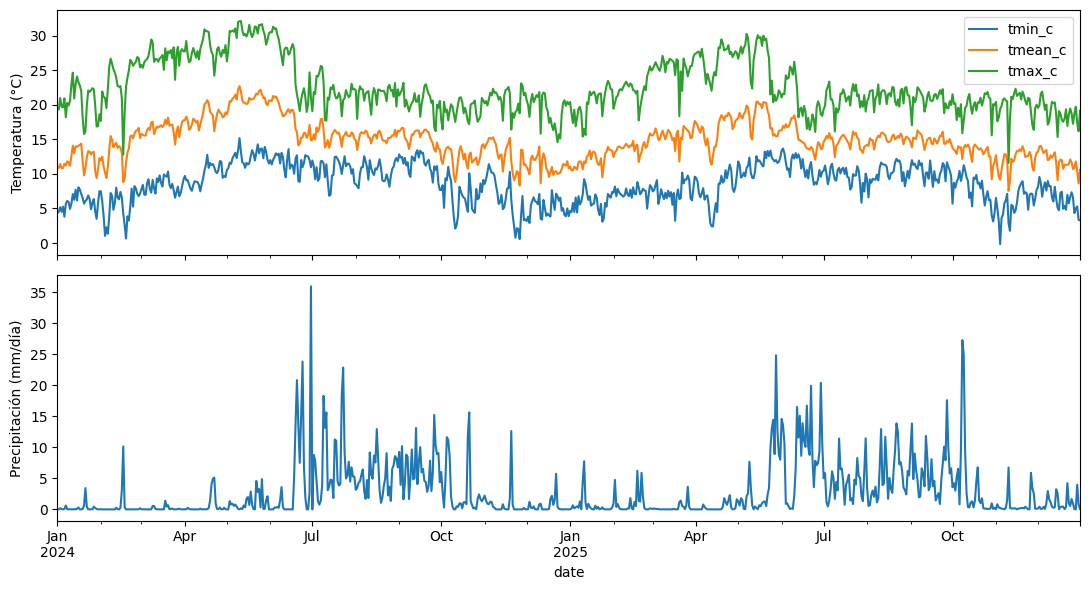

Temperatura fuera de orden: 0
Precipitación negativa: 0


In [21]:
if 'weather_daily' in TABLES:
    
    w = TABLES['weather_daily'].set_index('date')
    
    fig, axs = plt.subplots(2,1,figsize=(11,6),sharex=True)
    
    w[['tmin_c','tmean_c','tmax_c']].plot(ax=axs[0]); axs[0].set_ylabel('Temperatura (°C)')
    w['precip_mm'].plot(ax=axs[1]); axs[1].set_ylabel('Precipitación (mm/día)')
    
    plt.tight_layout()
    plt.show()
    
    # Validamos las temperatureas 
    print('Temperatura fuera de orden:',int(((w.tmin_c>w.tmean_c)|(w.tmean_c>w.tmax_c)).sum()))
    print('Precipitación negativa:',int((w.precip_mm<0).sum()))
    
else: print('NASA POWER sin datos; se omiten gráficos.')

Indicadores derivados que construiremos después con esta data:

| Indicador | Aplicación |
| --- | --- |
| Growing Degree Days (GDD) | Desarrollo fenológico de cultivos |
| Frecuencia de heladas | Riesgo climático y calendario de siembra |
| Días de calor extremo | Estrés térmico |
| Rachas secas | Riesgo de sequía durante el ciclo |
| Precipitación por temporada | Disponibilidad potencial de agua |
| Evapotranspiración de referencia (ET₀) | Demanda hídrica atmosférica |
| Variabilidad interanual | Evaluación de resiliencia climática |

## 4. NASA SRTM — elevación y pendiente aproximada (HTTP público)

SRTM (Shuttle Radar Topography Mission) fue una misión de NASA y NGA que utilizó radar para obtener información de elevación de gran parte de la superficie terrestre. 

Para la app, SRTM nos ayudará a caracterizar tres aspectos:

| Característica | ¿Por qué importa? | Uso posterior |
| --- | --- | --- |
| Elevación | Influye en el clima local y en la interpretación de datos meteorológicos | Evaluación de representatividad de NASA POWER |
| Pendiente | Influye en la escorrentía, erosión y manejo agrícola | Evaluación de riesgos y conservación del suelo |
| Variación topográfica | Diferentes partes de una parcela pueden comportarse de forma distinta | Caracterización de parcelas y manejo del agua |

Por ejemplo, dos terrenos podrían recibir precipitaciones similares, pero responder de manera diferente si uno es plano y otro está sobre una ladera. Se puede estudiar por lo tanto si las temperaturas de POWER necesitan una corrección por diferencias de elevación.

Una aproximación utiliza:

$$T_{\mathrm{parcela}}=T_{\mathrm{POWER}}-\Gamma(z_{\mathrm{parcela}}-z_{\mathrm{referencia}})$$

Donde:
- $T_{\mathrm{POWER}}$: temperatura reportada por NASA POWER.
- $z_{\mathrm{parcela}}$: elevación estimada de la parcela.
- $z_{\mathrm{referencia}}$: elevación representativa de los datos meteorológicos.
- $\Gamma$: gradiente térmico vertical asumido.

Un valor ilustrativo de $\Gamma$ es 0.0065 °C/m, aunque el gradiente real cambia según las condiciones atmosféricas.

La implementación utiliza **OpenTopoData**, un servicio público que permite consultar elevaciones de datasets como SRTM mediante HTTP. Es un intermediario que consulta datos topográficos; no es el servicio oficial de NASA Earthdata.

| Variable | Significado | Unidad | Procedencia |
| --- | --- | --- | --- |
| `elevation_m` | Elevación estimada del punto central | m | SRTM vía OpenTopoData |
| `slope_deg_approx` | Pendiente local aproximada | grados | Derivada de cinco elevaciones |
| `topography_samples` | Elevaciones de puntos vecinos | m | SRTM vía OpenTopoData |
| `spatial_resolution_m` | Resolución nominal del dataset | ~30 m | Metadatos SRTM |
| `slope_method` | Método utilizado | Diferencias centrales | Nuestro pipeline |

### ¿Cómo utilizaremos estos datos más adelante?

En el módulo agronómico podremos utilizarlos para contextualizar el riesgo de erosión, evaluar restricciones topográficas y estudiar diferencias de elevación con las fuentes climáticas. Sin embargo, la pendiente no determina por sí sola el riesgo de erosión. Para estimarlo necesitamos incorporar precipitación, suelo, cobertura vegetal y prácticas de manejo. También debemos reconocer que SRTM no ofrece cobertura adecuada en todas las latitudes. Para nuestra visión global, el conector deberá admitir otras fuentes de elevación cuando SRTM no esté disponible.

In [23]:
SRTM_URL = 'https://api.opentopodata.org/v1/srtm30m'

def get_srtm():
    
    #estos son desplazamientos espaciales respecto al punto central
    dlat = 0.00030   # equivale a 33 metros en dirección norte-sur
    dlon = 0.00030 / max(
        0.3, math.cos(math.radians(LAT))
    )

    # construimos un muestreo topográfico en todas direcciones y obtenemos elevación en cada punto
    xy = [
        (LAT, LON),
        (LAT+dlat, LON),
        (LAT-dlat, LON),
        (LAT, LON+dlon),
        (LAT, LON-dlon)
    ]
    
    # preparamos la consulta
    req = {
        'locations': '|'.join(
            f'{a:.6f},{b:.6f}' for a,b in xy
        )
    }

    # la ejecutamos
    data = http_json(SRTM_URL, req, 'srtm')
    points = pd.DataFrame([
        {
            'lat': r['location']['lat'],
            'lon': r['location']['lng'],
            'elevation_m': r['elevation']
        }
        for r in data['results']
    ])

    # si falta información devolvemos los puntos, pero sin calcular la pendiente
    if points.elevation_m.isna().any():
        return points, None

    dy = 2*dlat*111_320
    dx = 2*dlon*111_320*math.cos(math.radians(LAT))

    # Calcula la variación de elevación en dirección norte-sur
    dzdy = (
        points.loc[1,'elevation_m']
        - points.loc[2,'elevation_m']
    ) / dy

    # Calcula la variación en dirección este-oeste
    dzdx = (
        points.loc[3,'elevation_m']
        - points.loc[4,'elevation_m']
    ) / dx

    slope = math.degrees(
        math.atan(math.hypot(dzdy, dzdx))
    )

    return points, {
        'elevation_m': float(points.loc[0,'elevation_m']),
        'slope_deg_approx': slope
    }
    
result = try_fetch(
    'srtm',
    CONFIG['run_srtm'],
    get_srtm,
    url=SRTM_URL,
    scale='30m DEM'
)
TOPO={}
if result is not None:
    srtm_points, topo_info=result
    TOPO=topo_info or {}
    keep_table(
        'topography_samples',
        srtm_points,
        source='SRTM via OpenTopoData',
        resolution='30m',
        method='model_estimate'
    )
    print('Topografía resumida:',TOPO)

GET https://api.opentopodata.org/v1/srtm30m?locations=19.530000%2C-98.850000%7C19.530300%2C-98.850000%7C19.529700%2C-98.850000%7C19.530000%2C-98.849682%7C19.530000%2C-98.850318
[AVAILABLE    ] srtm


,lat,lon,elevation_m
0,19.5300,-98.850000,2271.0
1,19.5303,-98.850000,2272.0
2,19.5297,-98.850000,2270.0
3,19.5300,-98.849682,2273.0


Topografía resumida: {'elevation_m': 2271.0, 'slope_deg_approx': 3.830587969366151}


In [28]:
TABLES["topography_samples"]

,lat,lon,elevation_m
0,19.5300,-98.850000,2271.0
1,19.5303,-98.850000,2272.0
2,19.5297,-98.850000,2270.0
3,19.5300,-98.849682,2273.0
4,19.5300,-98.850318,2269.0


### Quality Checks

In [30]:
# ============================================================
# 4.1 — SRTM DATA QUALITY CHECKS
# ============================================================

SRTM_QUALITY = []

def check_srtm(test, condition, details=""):
    SRTM_QUALITY.append({
        "test": test,
        "status": "PASS" if bool(condition) else "FAIL",
        "details": str(details)
    })


# ------------------------------------------------------------
# 1. Disponibilidad de datos
# ------------------------------------------------------------

has_points = (
    "srtm_points" in globals()
    and isinstance(srtm_points, pd.DataFrame)
)

check_srtm(
    "SRTM DataFrame available",
    has_points
)

if not has_points:
    raise ValueError(
        "SRTM no devolvió un DataFrame. "
        "Revisa CATALOG y la respuesta HTTP."
    )

points = srtm_points.copy().reset_index(drop=True)


# ------------------------------------------------------------
# 2. Estructura y número de puntos
# ------------------------------------------------------------

required_columns = ["lat", "lon", "elevation_m"]

check_srtm(
    "Required columns",
    all(c in points.columns for c in required_columns)
)

check_srtm(
    "Expected five points",
    len(points) == 5,
    f"Received: {len(points)}"
)

if (
    not all(c in points.columns for c in required_columns)
    or len(points) != 5
):
    raise ValueError(
        "La respuesta SRTM no tiene la estructura esperada."
    )


# ------------------------------------------------------------
# 3. Coordenadas y orden de puntos
# ------------------------------------------------------------

check_srtm(
    "Valid latitude",
    points["lat"].between(-90, 90).all()
)

check_srtm(
    "Valid longitude",
    points["lon"].between(-180, 180).all()
)

dlat = 0.00030
dlon = 0.00030 / max(
    0.3, math.cos(math.radians(LAT))
)

expected_points = np.array([
    [LAT, LON],
    [LAT + dlat, LON],
    [LAT - dlat, LON],
    [LAT, LON + dlon],
    [LAT, LON - dlon]
])

actual_points = points[["lat", "lon"]].to_numpy(
    dtype=float
)

coordinate_match = np.allclose(
    actual_points,
    expected_points,
    atol=1e-5,
    rtol=0
)

check_srtm(
    "Point coordinates and order",
    coordinate_match,
    "Center, North, South, East, West"
)


# ------------------------------------------------------------
# 4. Elevaciones faltantes
# ------------------------------------------------------------

elevation = pd.to_numeric(
    points["elevation_m"],
    errors="coerce"
)

check_srtm(
    "No missing elevation",
    elevation.notna().all(),
    f"Missing: {elevation.isna().sum()}"
)

check_srtm(
    "Finite elevation values",
    np.isfinite(elevation.to_numpy()).all()
)


# ------------------------------------------------------------
# 5. Rangos físicos preliminares
# ------------------------------------------------------------

# Rango amplio para detectar errores evidentes.
# No sustituye la validación frente a un DEM o medición local.

valid_elevation = elevation.between(-500, 9000)

check_srtm(
    "Elevation plausibility",
    valid_elevation.all(),
    f"Outside screening range: {(~valid_elevation).sum()}"
)


# ------------------------------------------------------------
# 6. Pendiente calculada
# ------------------------------------------------------------

slope = TOPO.get("slope_deg_approx")

valid_slope = (
    slope is not None
    and np.isfinite(slope)
    and 0 <= slope < 90
)

check_srtm(
    "Slope angle validity",
    valid_slope,
    f"Slope: {slope} degrees"
)


# ------------------------------------------------------------
# 7. Recalcular pendiente independientemente
# ------------------------------------------------------------

if (
    elevation.notna().all()
    and np.isfinite(elevation.to_numpy()).all()
    and coordinate_match
):
    dy = 2 * dlat * 111_320
    dx = (
        2 * dlon * 111_320
        * math.cos(math.radians(LAT))
    )

    dzdy = (elevation.iloc[1] - elevation.iloc[2]) / dy
    dzdx = (elevation.iloc[3] - elevation.iloc[4]) / dx

    slope_recalculated = math.degrees(
        math.atan(math.hypot(dzdy, dzdx))
    )

    slope_consistent = (
        valid_slope
        and np.isclose(
            slope,
            slope_recalculated,
            atol=1e-8
        )
    )

else:
    slope_recalculated = np.nan
    slope_consistent = False

check_srtm(
    "Slope calculation consistency",
    slope_consistent,
    f"Recalculated slope: {slope_recalculated}"
)


# ------------------------------------------------------------
# 8. Elevación central consistente
# ------------------------------------------------------------

center_elevation = TOPO.get("elevation_m")

center_consistent = (
    center_elevation is not None
    and pd.notna(elevation.iloc[0])
    and np.isclose(
        center_elevation,
        elevation.iloc[0],
        atol=1e-8
    )
)

check_srtm(
    "Center elevation consistency",
    center_consistent
)


# ------------------------------------------------------------
# 9. Reporte final
# ------------------------------------------------------------

srtm_quality_report = pd.DataFrame(SRTM_QUALITY)

display(srtm_quality_report)

print("SRTM QUALITY SUMMARY")
print(srtm_quality_report["status"].value_counts())

TABLES["srtm_quality_report"] = (
    srtm_quality_report.copy()
)

,test,status,details
0,SRTM DataFrame available,PASS,
1,Required columns,PASS,
2,Expected five points,PASS,Received: 5
3,Valid latitude,PASS,
4,Valid longitude,PASS,
5,Point coordinates and order,PASS,"Center, North, South, East, West"
6,No missing elevation,PASS,Missing: 0
7,Finite elevation values,PASS,
8,Elevation plausibility,PASS,Outside screening range: 0
9,Slope angle validity,PASS,Slope: 3.830587969366151 degrees


SRTM QUALITY SUMMARY
status
PASS    12
Name: count, dtype: int64


### Gradiente Topográfico

La gráfica muestra cómo cambian las elevaciones alrededor de la coordenada del agricultor. No será todavía un mapa continuo del relieve, únicamente mostrará los cinco puntos muestreados.

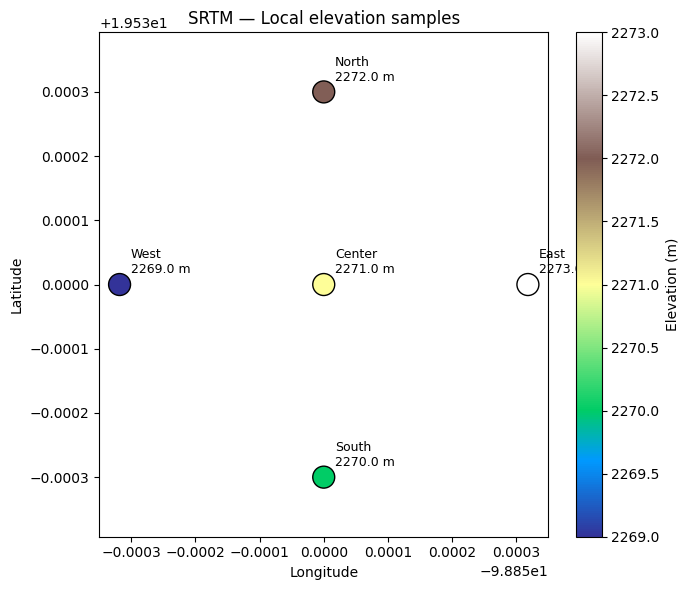

Center elevation: 2271.0 m
Approximate slope: 3.830587969366151°


In [32]:
# ============================================================
# 4.2 — SRTM TOPOGRAPHIC VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

points = srtm_points.copy()

labels = ["Center", "North", "South", "East", "West"]

fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    points["lon"],
    points["lat"],
    c=points["elevation_m"],
    cmap="terrain",
    s=250,
    edgecolors="black"
)

for i, row in points.iterrows():
    ax.annotate(
        f"{labels[i]}\n{row['elevation_m']:.1f} m",
        (row["lon"], row["lat"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9
    )

plt.colorbar(scatter, ax=ax, label="Elevation (m)")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("SRTM — Local elevation samples")

ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

print(f"Center elevation: {TOPO.get('elevation_m')} m")
print(f"Approximate slope: {TOPO.get('slope_deg_approx')}°")

## 5. SoilGrids — propiedades edáficas por profundidad (WCS)

Podemos conocer perfectamente la precipitación de una región, pero sin información del suelo no podemos estimar adecuadamente cuánta agua podría retenerse, qué limitaciones químicas existen o cómo podrían responder distintas especies.

**1. ¿Por qué necesitamos SoilGrids?**   

SoilGrids ofrece predicciones espaciales de propiedades del suelo a una resolución nominal de 250 metros, incluyendo distintos intervalos de profundidad. Una precisión científica: SoilGrids no es una base de mediciones directas de nuestra parcela. Utiliza modelos estadísticos de cartografía digital de suelos, entrenados a partir de observaciones y variables ambientales. ***Sus estimaciones incorporan incertidumbre***.

Obtendremos las siguientes variables:

| Propiedad | Código | ¿Para qué sirve en FarmAdapt? |
| --- | --- | --- |
| pH | `phh2o` | Compatibilidad de cultivos y posibles limitaciones de nutrientes |
| Carbono orgánico | `soc` | Indicador relacionado con materia orgánica y funcionamiento del suelo |
| Arcilla | `clay` | Textura, retención de agua y propiedades físicas |
| Arena | `sand` | Textura, drenaje y comportamiento hídrico |
| Limo | `silt` | Clasificación textural |
| Nitrógeno total | `nitrogen` | Caracterización general del contenido de nitrógeno |
| Densidad aparente | `bdod` | Propiedades físicas, almacenamiento de agua y cálculos de stocks |
| Capacidad de intercambio catiónico | `cec` | Capacidad del suelo para retener e intercambiar cationes |
| Fragmentos gruesos | `cfvo` | Volumen ocupado por fragmentos gruesos |
| Contenido volumétrico de agua | `wv0010`, `wv003`, `wv1500` | Aproximaciones para evaluar características de retención de agua |


La información no se proporciona únicamente para la superficie, sino para seis intervalos:
* **Capas superficiales:** Importantes para procesos relacionados con materia orgánica, establecimiento del cultivo y propiedades químicas.
* **Capas profundas:** Pueden aportar información relevante para raíces, almacenamiento potencial de agua y limitaciones del subsuelo.


La API REST oficial está **temporalmente suspendida** según ISRIC. Mostramos la solicitud real mediante WCS, recomendado por ISRIC para subconjuntos. Requiere `pip install owslib rasterio`. Se usa una ventana pequeña EPSG:4326; si el servidor rechaza el CRS, se reporta error y **no** se inventa valor. Para producción, usar CRS/proyección Homolosine del producto y verificar su escala antes de agregaciones. Descargamos mediana y límites de predicción cuando el servicio los soporte.

Propiedades: `bdod` (densidad aparente), `cec`, `cfvo` (fragmentos gruesos), `clay`, `nitrogen`, `ocd`, `ocs`, `phh2o`, `sand`, `silt`, `soc`, `wv0010`, `wv0033`, `wv1500`. No todas son necesarias para el MVP, pero aquí se registra su consulta.

https://docs.isric.org/globaldata/soilgrids/WCS_from_Python.html

SoilGrids almacena muchas propiedades como números enteros escalados para reducir el espacio de almacenamiento. Por ejemplo:

| Propiedad | Valor crudo hipotético | Conversión | Valor convencional |
| --- | --- | --- | --- |
| pH | 65 | ÷ 10 | 6.5 |
| SOC | 250 | ÷ 10 | 25 g/kg |
| Arcilla | 350 | ÷ 10 | 35 % |
| Nitrógeno | 180 | ÷ 100 | 1.8 g/kg |
| Densidad aparente | 135 | ÷ 100 | 1.35 kg/dm³ |

Si nuestro notebook descarga un valor crudo de pH igual a 65 y no aplica la conversión, estaríamos introduciendo información incorrecta al FarmProfile.

In [ ]:
# 7 mins approx all data
from owslib.wcs import WebCoverageService
from rasterio.io import MemoryFile
from pyproj import CRS

# Divisores y unidades CONVENCIONALES publicados por ISRIC.
SOIL_SPECS = {
    'bdod': (100, 'kg/dm3'), 'cec': (10, 'cmol(c)/kg'),
    'cfvo': (10, 'vol%'), 'clay': (10, '%'),
    'nitrogen': (100, 'g/kg'), 'ocd': (10, 'kg/m3'),
    'ocs': (10, 'kg/m2'), 'phh2o': (10, 'pH'),
    'sand': (10, '%'), 'silt': (10, '%'),
    'soc': (10, 'g/kg'), 'wv0010': (10, 'vol%'),
    'wv0033': (10, 'vol%'), 'wv1500': (10, 'vol%')
}
SOIL_STATS = ('mean', 'Q0.05', 'Q0.5', 'Q0.95')
SOIL_DEPTHS = ('0-5cm', '5-15cm', '15-30cm', '30-60cm', '60-100cm', '100-200cm')

# Ejecutar primero 'pilot'; cambia a 'all' para el catálogo completo.
SOIL_SCOPE = 'all'  # 'pilot' | 'all'
SOIL_PILOT_PROPERTIES = [
    "phh2o",
    "soc",
    "clay",
    "sand",
    "silt",
    "bdod",
    "nitrogen",
    "wv003",
    "wv1500"
]
SOIL_PILOT_DEPTHS = [
    "0-5cm",
    "5-15cm",
    "15-30cm",
    "30-60cm"
]
SOIL_MAX_REQUESTS = None  # opcional: 20 para limitar pruebas; None = todas
SOIL_RADIUS_DEG = 0.004
SOIL_OUTPUT_RES_DEG = 0.002   # ~200 m; no confundir con resolución nativa 250 m
SOIL_CACHE_DIR = Path(RAW) / 'soilgrids'
SOIL_CACHE_DIR.mkdir(parents=True, exist_ok=True)

SOIL_STATS_QUICK = ["mean"]
SOIL_STATS_FULL = ["mean", "Q0.05", "Q0.5", "Q0.95"]


# API CURRENTLY SUSPENDED
SOIL_DOC='https://docs.isric.org/globaldata/soilgrids/'

# Auditar individualmente todas las solicitudes, incluso las fallidas.
soilgrids_request_log = []

def get_soilgrids():
    rows = []
    requested = 0
    required_crs = CRS.from_epsg(4326)
    bbox = (LON-SOIL_RADIUS_DEG, LAT-SOIL_RADIUS_DEG,
            LON+SOIL_RADIUS_DEG, LAT+SOIL_RADIUS_DEG)

    names = (SOIL_PILOT_PROPERTIES if SOIL_SCOPE == 'pilot'
             else tuple(SOIL_SPECS))
    wanted_depths = (SOIL_PILOT_DEPTHS if SOIL_SCOPE == 'pilot'
                     else SOIL_DEPTHS + ('0-30cm',))

    for prop in names:
        service = f'https://maps.isric.org/mapserv?map=/map/{prop}.map'
        try:
            wcs = WebCoverageService(service, version='1.0.0', timeout=90)
            offered = set(wcs.contents)
        except Exception as exc:
            soilgrids_request_log.append({
                'property':prop, 'coverage':None, 'status':'metadata_error',
                'error':str(exc)[:300]
            })
            continue

        for depth in wanted_depths:
            for statistic in SOIL_STATS:
                cid = f'{prop}_{depth}_{statistic}'
                # Las coberturas deben estar anunciadas por el servidor.
                if cid not in offered:
                    continue
                if SOIL_MAX_REQUESTS is not None and requested >= SOIL_MAX_REQUESTS:
                    print('Límite de solicitudes alcanzado:', SOIL_MAX_REQUESTS)
                    return pd.DataFrame(rows)
                requested += 1
                query_signature = json.dumps({
                    'coverage': cid, 'bbox': bbox,
                    'resolution_deg': SOIL_OUTPUT_RES_DEG,
                    'crs': 'EPSG:4326'
                }, sort_keys=True)
                key = hashlib.sha256(query_signature.encode('utf-8')).hexdigest()[:12]
                path = SOIL_CACHE_DIR / f'{cid}_{key}.tif'
                try:
                    if CONFIG.get('cache', True) and path.exists():
                        payload = path.read_bytes()
                        cached = True
                    else:
                        response = wcs.getCoverage(
                            identifier=cid,
                            crs='urn:ogc:def:crs:EPSG::4326',
                            bbox=bbox,
                            resx=SOIL_OUTPUT_RES_DEG,
                            resy=SOIL_OUTPUT_RES_DEG,
                            format='GEOTIFF_INT16'
                        )
                        payload = response.read()
                        cached = False
                    with MemoryFile(payload) as memory:
                        with memory.open() as ras:
                            if ras.crs is None or not CRS.from_wkt(ras.crs.to_wkt()).equals(
                                required_crs, ignore_axis_order=True
                            ):
                                raise ValueError(f'CRS inesperado: {ras.crs}')
                            if not (ras.bounds.left <= LON <= ras.bounds.right and
                                    ras.bounds.bottom <= LAT <= ras.bounds.top):
                                raise ValueError('El ráster no contiene la ubicación del agricultor')
                            band = ras.read(1, masked=True)
                            rr, cc = ras.index(LON, LAT)
                            if not (0 <= rr < ras.height and 0 <= cc < ras.width):
                                raise ValueError('Píxel central fuera del ráster')
                            sample = band[rr, cc]
                            raw_value = np.nan if np.ma.is_masked(sample) else float(sample)
                            raw_median = (float(np.median(band.compressed()))
                                          if band.count() else np.nan)
                            if not np.isfinite(raw_value):
                                raise ValueError('Píxel central sin datos')
                            raster_bounds = tuple(map(float, ras.bounds))
                            raster_shape = f'{ras.height}x{ras.width}'
                            raster_crs = ras.crs.to_wkt()
                            n_valid = int(band.count())
                    if not cached:
                        path.write_bytes(payload)  # únicamente tras validar GeoTIFF
                        time.sleep(0.25)
                    factor, unit = SOIL_SPECS[prop]
                    rows.append({
                        'farm_id':FARMER_INPUT['farm_id'], 'property':prop,
                        'depth_cm':depth, 'statistic':statistic,
                        'raw_value':raw_value, 'value':raw_value/factor,
                        'spatial_median_value':raw_median/factor,
                        'unit':unit, 'conversion_divisor':factor,
                        'n_valid_pixels':n_valid, 'raster_shape':raster_shape,
                        'raster_bounds':raster_bounds, 'raster_crs':raster_crs,
                        'source':'ISRIC SoilGrids WCS', 'origin':'model_estimate',
                        'cache_hit':cached, 'raster_file':str(path),
                        'status':'available'
                    })
                    soilgrids_request_log.append({
                        'property':prop, 'coverage':cid,
                        'status':'available', 'cache_hit':cached, 'error':None
                    })
                    print(f'{cid}: {raw_value/factor:.3f} {unit}' +
                          (' [cache]' if cached else ''))
                except Exception as exc:
                    soilgrids_request_log.append({
                        'property':prop, 'coverage':cid,
                        'status':'error', 'cache_hit':None,
                        'error':str(exc)[:300]
                    })
                    print(f'{cid}: ERROR — {exc}')
    if not rows:
        raise RuntimeError('SoilGrids no produjo ninguna observación válida')
    return pd.DataFrame(rows)

# Ejecutamos el soilgrids data retrieval: Approx 20s para 4 estadísticos de 3 propieddes a 0-5cms
CONFIG['run_soilgrids_wcs'] = True
soil = try_fetch(
    'soilgrids_wcs',
    CONFIG['run_soilgrids_wcs'],
    get_soilgrids,
    url=SOIL_DOC,
    scale='250m native; sampled WCS grid'
)
soil_requests = pd.DataFrame(soilgrids_request_log)

if not soil_requests.empty:
    display(soil_requests.groupby('status').size().to_frame('requests'))
    TABLES['soilgrids_request_log'] = soil_requests.copy()

bdod_0-5cm_mean: 1.310 kg/dm3 [cache]
bdod_0-5cm_Q0.05: 0.870 kg/dm3 [cache]
bdod_0-5cm_Q0.5: 1.320 kg/dm3 [cache]
bdod_0-5cm_Q0.95: 1.680 kg/dm3 [cache]
bdod_5-15cm_mean: 1.330 kg/dm3 [cache]
bdod_5-15cm_Q0.05: 0.980 kg/dm3 [cache]
bdod_5-15cm_Q0.5: 1.310 kg/dm3 [cache]
bdod_5-15cm_Q0.95: 1.690 kg/dm3 [cache]
bdod_15-30cm_mean: 1.350 kg/dm3 [cache]
bdod_15-30cm_Q0.05: 1.000 kg/dm3 [cache]
bdod_15-30cm_Q0.5: 1.350 kg/dm3 [cache]
bdod_15-30cm_Q0.95: 1.700 kg/dm3 [cache]
bdod_30-60cm_mean: 1.330 kg/dm3 [cache]
bdod_30-60cm_Q0.05: 0.860 kg/dm3 [cache]
bdod_30-60cm_Q0.5: 1.330 kg/dm3 [cache]
bdod_30-60cm_Q0.95: 1.720 kg/dm3 [cache]
bdod_60-100cm_mean: 1.360 kg/dm3 [cache]
bdod_60-100cm_Q0.05: 0.900 kg/dm3 [cache]
bdod_60-100cm_Q0.5: 1.400 kg/dm3 [cache]
bdod_60-100cm_Q0.95: 1.830 kg/dm3 [cache]
bdod_100-200cm_mean: 1.370 kg/dm3 [cache]
bdod_100-200cm_Q0.05: 0.860 kg/dm3 [cache]
bdod_100-200cm_Q0.5: 1.400 kg/dm3 [cache]
bdod_100-200cm_Q0.95: 1.830 kg/dm3 [cache]
cec_0-5cm_mean: 29.400 cmol(

,requests
status,
available,316


Para que el retrieval sea mas eficiente, podríamos separar la ingesta en tres niveles:

* Nivel 1 Perfil rápido — ubicación nueva    
    Consultar propiedades prioritarias hasta 30–60 cm, usando caché y datos disponibles. Mostrar resultados preliminares y limitaciones.

* Nivel 2 Perfil completo — cuatro regiones piloto    
    Precomputar todas las profundidades, propiedades necesarias, cuantiles y simulaciones agronómicas. Esto será lo que utilizaremos en el demo.

* Nivel 3 Perfil avanzado — modelación específica    
    Descargar capas adicionales únicamente cuando el cultivo, su profundidad radicular y el modelo realmente las requieran.

* Save data in cache and TABLES dictionary

In [79]:
if isinstance(soil, pd.DataFrame) and not soil.empty:
    # Guardamos la tabla raw
    print("Raw data table")
    keep_table(
        'soil_properties_raw',
        soil,
        source='ISRIC SoilGrids WCS',
        resolution='native ~250m; requested angular grid ~0.002 degrees',
        unit_notes='raw_value es entero escalado; value ya está convertido',
        method='model_estimate'
    )
    
    # Una fila por propiedad y profundidad; cuatro columnas de estadísticos.
    idx = ['farm_id', 'property', 'depth_cm', 'unit']
    soil_properties = (soil.pivot_table(index=idx, columns='statistic',
                                       values='value', aggfunc='first')
                       .reset_index().rename_axis(None, axis=1))
    soil_properties = soil_properties.rename(columns={
        'Q0.05':'q05', 'Q0.5':'q50', 'Q0.95':'q95'
    })
    for col in ('mean', 'q05', 'q50', 'q95'):
        if col not in soil_properties:
            soil_properties[col] = np.nan
    
    soil_properties['source'] = 'ISRIC SoilGrids WCS'
    soil_properties['origin'] = 'model_estimate'
    
    soil_properties['interval_90_width'] = (
        soil_properties['q95'] - soil_properties['q05'])
    
    # Guardamos una tabla con las propiedades procesadas
    print("Processed data table")
    keep_table(
        'soil_properties',
        soil_properties,
        source='ISRIC SoilGrids WCS',
        resolution='~250m native',
        unit_notes='ISRIC conventional units; 90% predictive interval',
        method='model_estimate'
    )

Raw data table


,farm_id,property,depth_cm,statistic,raw_value,value,spatial_median_value,unit,conversion_divisor,n_valid_pixels,raster_shape,raster_bounds,raster_crs,source,origin,cache_hit,raster_file,status
0,texcoco_demo,bdod,0-5cm,mean,131.0,1.31,1.310,kg/dm3,100,16,4x4,"(-98.854, 19.526000000000003, -98.846, 19.5340...","GEOGCS[""WGS 84"",DATUM[""World Geodetic System 1...",ISRIC SoilGrids WCS,model_estimate,True,data/farms/texcoco_demo/raw/soilgrids/bdod_0-5...,available
1,texcoco_demo,bdod,0-5cm,Q0.05,87.0,0.87,0.895,kg/dm3,100,16,4x4,"(-98.854, 19.526000000000003, -98.846, 19.5340...","GEOGCS[""WGS 84"",DATUM[""World Geodetic System 1...",ISRIC SoilGrids WCS,model_estimate,True,data/farms/texcoco_demo/raw/soilgrids/bdod_0-5...,available
2,texcoco_demo,bdod,0-5cm,Q0.5,132.0,1.32,1.320,kg/dm3,100,16,4x4,"(-98.854, 19.526000000000003, -98.846, 19.5340...","GEOGCS[""WGS 84"",DATUM[""World Geodetic System 1...",ISRIC SoilGrids WCS,model_estimate,True,data/farms/texcoco_demo/raw/soilgrids/bdod_0-5...,available
3,texcoco_demo,bdod,0-5cm,Q0.95,168.0,1.68,1.690,kg/dm3,100,16,4x4,"(-98.854, 19.526000000000003, -98.846, 19.5340...","GEOGCS[""WGS 84"",DATUM[""World Geodetic System 1...",ISRIC SoilGrids WCS,model_estimate,True,data/farms/texcoco_demo/raw/soilgrids/bdod_0-5...,available


Processed data table


,farm_id,property,depth_cm,unit,q05,q50,q95,mean,source,origin,interval_90_width
0,texcoco_demo,bdod,0-5cm,kg/dm3,0.87,1.32,1.68,1.31,ISRIC SoilGrids WCS,model_estimate,0.81
1,texcoco_demo,bdod,100-200cm,kg/dm3,0.86,1.40,1.83,1.37,ISRIC SoilGrids WCS,model_estimate,0.97
2,texcoco_demo,bdod,15-30cm,kg/dm3,1.00,1.35,1.70,1.35,ISRIC SoilGrids WCS,model_estimate,0.70
3,texcoco_demo,bdod,30-60cm,kg/dm3,0.86,1.33,1.72,1.33,ISRIC SoilGrids WCS,model_estimate,0.86


### Data Quality Check

In [80]:
if isinstance(soil, pd.DataFrame) and not soil.empty:
    # Validación: cuantiles y propiedades con restricciones conocidas.
    complete = soil_properties[['q05', 'q50', 'q95']].notna().all(axis=1)
    order_ok = (soil_properties['q05'] <= soil_properties['q50']) & (
        soil_properties['q50'] <= soil_properties['q95'])
    soil_properties['quantile_check'] = np.where(
        ~complete, 'INCOMPLETE', np.where(order_ok, 'PASS', 'FAIL'))
    ranges = {'phh2o':(0,14), 'clay':(0,100), 'sand':(0,100),
              'silt':(0,100), 'cfvo':(0,100),
              'wv0010':(0,100), 'wv003':(0,100), 'wv1500':(0,100)}
    
    def plausible(row):
        if pd.isna(row['mean']): return 'INCOMPLETE'
        lo, hi = ranges.get(row['property'], (0, np.inf))
        return 'PASS' if lo <= row['mean'] <= hi else 'FAIL'
    
    soil_properties['range_check'] = soil_properties.apply(plausible, axis=1)
    soil_quality = soil_properties[['property','depth_cm','quantile_check','range_check']]
    TABLES['soil_properties'] = soil_properties.copy()
    TABLES['soil_quality_report'] = soil_quality.copy()
    display(soil_quality)

    # Comprobación exploratoria de textura; pueden existir diferencias
    # por predicciones independientes, no se fuerza la suma a 100.
    texture = (soil_properties[soil_properties['property'].isin(['sand','silt','clay'])]
               .pivot_table(index='depth_cm', columns='property',
                            values='mean', aggfunc='first'))
    if all(c in texture.columns for c in ('sand','silt','clay')):
        texture['total_pct'] = texture[['sand','silt','clay']].sum(axis=1)
        texture['deviation_from_100'] = texture['total_pct'] - 100
        display(texture)

    out = Path(STD)
    out.mkdir(parents=True, exist_ok=True)
    soil.to_parquet(out/'soil_properties_raw.parquet', index=False)
    soil_properties.to_parquet(out/'soil_properties.parquet', index=False)
    soil_requests.to_csv(out/'soilgrids_requests.csv', index=False)
    soil_quality.to_csv(out/'soil_quality.csv', index=False)
    print('Archivos exportados en:', out)


,property,depth_cm,quantile_check,range_check
0,bdod,0-5cm,PASS,PASS
1,bdod,100-200cm,PASS,PASS
2,bdod,15-30cm,PASS,PASS
3,bdod,30-60cm,PASS,PASS
4,bdod,5-15cm,PASS,PASS
...,...,...,...,...
74,wv1500,100-200cm,PASS,PASS
75,wv1500,15-30cm,PASS,PASS
76,wv1500,30-60cm,PASS,PASS
77,wv1500,5-15cm,PASS,PASS


property,clay,sand,silt,total_pct,deviation_from_100
depth_cm,,,,,
0-5cm,28.1,48.9,23.0,100.0,0.0
100-200cm,35.6,41.3,23.1,100.0,0.0
15-30cm,30.8,46.6,22.6,100.0,0.0
30-60cm,33.6,43.3,23.1,100.0,0.0
5-15cm,28.4,48.1,23.4,99.9,-0.1
60-100cm,36.4,39.3,24.3,100.0,0.0


Archivos exportados en: data/farms/texcoco_demo/standardized


## 6. MODIS — NDVI/EVI, LST y ET por API REST de ORNL DAAC

La API `/rst/api/v1/{product}/dates` muestra fechas reales; `/subset` obtiene hasta 10 fechas MODIS por solicitud. **No hay descarga global.** Para la demostración pedimos un pixel/subset 0 km. `MOD13Q1` vegetación, `MOD11A2` temperatura superficial y `MOD16A2GF` evapotranspiración. Las bandas y escalas se consultan por `/bands`. Los valores crudos **no se interpretan** hasta revisar el factor de escala y QA.

https://modis.ornl.gov/data/modis_webservice.html

In [ ]:
ORNL_BASE='https://modis.ornl.gov/rst/api/v1'
MODIS_PRODUCTS={'MOD13Q1':['NDVI','EVI'],'MOD11A2':['LST_Day_1km','LST_Night_1km'],
                'MOD16A2GF':['ET','PET']}
def get_modis_product(product):
    bands=http_json(f'{ORNL_BASE}/{product}/bands',cache_key=f'{product}_bands')
    dates=http_json(f'{ORNL_BASE}/{product}/dates',{'latitude':LAT,'longitude':LON},f'{product}_dates')
    # fechas AYYYYDDD -> datetime
    available=dates.get('dates',[])
    filtered=[]
    for rec in available:
        date_str=rec.get('modis_date')
        if not date_str: continue
        try: d=datetime.strptime(date_str,'A%Y%j').date()
        except ValueError: continue
        if CONFIG['modis_start']<=d.isoformat()<=CONFIG['modis_end']: filtered.append(date_str)
    print(product,'fechas encontradas:',len(filtered),'band metadata:',str(bands)[:400])
    records=[]
    for start in range(0,len(filtered),10):
        batch=filtered[start:start+10]
        data=http_json(f'{ORNL_BASE}/{product}/subset',{
           'latitude':LAT,'longitude':LON,'startDate':batch[0],'endDate':batch[-1],
           'kmAboveBelow':0,'kmLeftRight':0},f'{product}_subset_{start}')
        for item in data.get('subset',[]):
            vals=item.get('data',[])
            records.append({'product':product,'date':datetime.strptime(item['calendar_date'],'%Y-%m-%d').date(),
               'band':item.get('band'),'value_raw':float(vals[0]) if vals and vals[0] is not None else np.nan,
               'modis_date':item.get('modis_date')})
    return pd.DataFrame(records)
MODIS_TABLES={}
for product in MODIS_PRODUCTS:
    df=try_fetch('modis_'+product,CONFIG['run_modis_ornl'],lambda p=product:get_modis_product(p),
                 url=f'{ORNL_BASE}/{product}/subset',scale='250m / 500m / 1km depending on product')
    if isinstance(df,pd.DataFrame) and not df.empty:
        MODIS_TABLES[product]=df
        keep_table('modis_'+product.lower()+'_raw',df,source='NASA MODIS ORNL DAAC',
           resolution='16d/8d composite',unit_notes='RAW — use QA and scale factor from product metadata')

## 7. Earth Engine (alternativa para algunos productos; SMAP tiene acceso Earthdata directo) — acceso a colecciones globales masivas

**Opcional**. Google Earth Engine NO es una API pública anónima: requiere registro, autenticación y proyecto habilitado. El código muestra las colecciones concretas, cómo filtrarlas por ubicación/fecha y cómo devolver una serie al cliente. Si no se configura, todas quedarán en `not_requested`, no en `missing`.

La llamada principal del cliente es `ee.ImageCollection(...).filterDate(...).select(...).getRegion(...)` o `reduceRegion`. Los objetos se evalúan en servidor: `getInfo()` provoca la transferencia. Se aplican límites muy pequeños para evitar exceder cuotas.

In [ ]:
EE=None
def init_ee():
    global EE
    import ee
    if not CONFIG['ee_project']:
        raise RuntimeError('Configura EE_PROJECT_ID y autentícate con earthengine authenticate')
    ee.Initialize(project=CONFIG['ee_project'])
    EE=ee
    print('Google Earth Engine inicializado; proyecto:', CONFIG['ee_project'])
    return ee
if CONFIG['run_earth_engine']:
    try: init_ee()
    except Exception as e:
        log_source('earth_engine_auth','error',access='Earth Engine account',error=e)
        EE=None
else:
    log_source('earth_engine_auth','not_requested',access='Earth Engine account')

def ee_point_timeseries(collection_id, bands, start, end, *, scale, transform=None, limit=300):
    if EE is None: raise RuntimeError('Earth Engine no disponible o no inicializado')
    point=EE.Geometry.Point([LON,LAT])
    coll=EE.ImageCollection(collection_id).filterBounds(point).filterDate(start,end).select(bands)
    count=coll.size().getInfo()
    print('EE.ImageCollection:',collection_id, '| images:',count, '|',start,end)
    if count>limit: raise ValueError(f'{count} imágenes supera limit={limit}; acorta ventana o agrega en servidor')
    # getRegion devuelve cabecera + filas para punto; escala expresada en metros
    result=coll.getRegion(point,scale).getInfo()
    if len(result)<2: return pd.DataFrame(columns=['date']+bands)
    df=pd.DataFrame(result[1:],columns=result[0])
    df['date']=pd.to_datetime(df['time'],unit='ms',utc=True)
    df=df[['date']+bands].sort_values('date')
    if transform is not None: df=transform(df)
    df['farm_id']=FARMER_INPUT['farm_id']
    return df

## 8. GPM IMERG V07 — lluvia extrema subdiaria

Usamos el producto de media hora y convertimos **tasa** de precipitación (mm/h) a acumulación de 30 minutos multiplicando por 0.5; luego agregamos por fecha UTC. El periodo por defecto es un mes. **GPM no representa intensidad de precipitación a escala de una parcela de pocos metros**.

https://developers.google.com/earth-engine/datasets/catalog/NASA_GPM_L3_IMERG_V07

In [ ]:
def get_gpm():
    df=ee_point_timeseries('NASA/GPM_L3/IMERG_V07',['precipitation'],
                           CONFIG['ee_start'],CONFIG['ee_end'],scale=11000,limit=1600)
    df['rain_30min_mm']=pd.to_numeric(df['precipitation'],errors='coerce')*0.5
    df['utc_date']=df['date'].dt.floor('D')
    daily=df.groupby('utc_date',as_index=False).agg(gpm_precip_mm=('rain_30min_mm','sum'),
                     samples=('rain_30min_mm','count'),max_30min_mm=('rain_30min_mm','max'))
    daily['complete_48_slots']=daily['samples'].eq(48)
    # Incompletos deben figurar como NaN, no como días secos
    daily.loc[~daily.complete_48_slots,'gpm_precip_mm']=np.nan
    return df,daily
gpm=try_fetch('gpm_imerg_v07',EE is not None,get_gpm,
  url='https://developers.google.com/earth-engine/datasets/catalog/NASA_GPM_L3_IMERG_V07',
  access='Earth Engine',scale='~0.1° / 30 min')
if gpm is not None:
    keep_table('gpm_half_hourly',gpm[0],source='NASA GPM IMERG V07 via EE',resolution='30 min')
    keep_table('gpm_daily',gpm[1],source='NASA GPM IMERG V07 via EE',resolution='daily aggregated')

## 9. MODIS vía Earth Engine: NDVI, EVI, LST, ET, LAI

Esta ruta se ofrece como alternativa a ORNL. Las escalas son **distintas por producto**. Los factores de escala se aplican explícitamente aquí y deben revisarse con la versión del catálogo. Las observaciones de NDVI bajas *no prueban* suelo desnudo sin QA ni validación parcelaria.

In [ ]:
EE_MODIS={
 'ndvi_evi':('MODIS/061/MOD13Q1',['NDVI','EVI'],250,{'NDVI':0.0001,'EVI':0.0001}),
 'lst':('MODIS/061/MOD11A2',['LST_Day_1km','LST_Night_1km'],1000,{'LST_Day_1km':0.02,'LST_Night_1km':0.02}),
 'et_pet':('MODIS/061/MOD16A2GF',['ET','PET'],500,{'ET':0.1,'PET':0.1}),
 'lai_fpar':('MODIS/061/MOD15A2H',['Lai_500m','Fpar_500m'],500,{'Lai_500m':0.1,'Fpar_500m':0.01})
}
def get_ee_modis(config_key):
    collection,bands,scale,factors=EE_MODIS[config_key]
    df=ee_point_timeseries(collection,bands,CONFIG['ee_start'],CONFIG['ee_end'],scale=scale,limit=100)
    for band in bands:
        df[band]=pd.to_numeric(df[band],errors='coerce')*factors[band]
    if config_key=='lst':
        for band in bands: df[band+'_c']=df[band]-273.15
    return df
for key,(collection,bands,scale,factors) in EE_MODIS.items():
    df=try_fetch('ee_modis_'+key,EE is not None,lambda k=key:get_ee_modis(k),
               url=f'https://developers.google.com/earth-engine/datasets/catalog/{collection.replace("/","_")}',
               access='Earth Engine',scale=f'{scale}m composite')
    if isinstance(df,pd.DataFrame) and not df.empty:
        keep_table('modis_'+key,df,source=collection+' via EE',resolution=f'{scale}m')

## 10. NASA SMAP (Earthdata Login) — ruta principal mediante `earthaccess`

**Esta es la ruta directa de NASA recomendada para usuarios con Earthdata Login**. La autenticación sucede en tu máquina; **nunca escribas usuario, contraseña o tokens en las celdas**. `earthaccess` busca granules en CMR por fecha y región y descarga los archivos HDF5 originales de NSIDC. No utiliza Google Earth Engine ni funciones de Claude.

Elegimos `SPL4SMGP`, **versión `008`** (SMAP L4 Global 3-hourly 9 km Soil Moisture Geophysical Data). Contiene humedad superficial (0–5 cm) y de zona radicular (0–100 cm) a escala aproximada de **9 km**. Es una estimación de asimilación en modelo terrestre, **no una medición puntual de la parcela**.

1. Con `run_smap_earthdata=False`, se registra `not_requested` y no se inicia sesión.
2. Al activarlo, `earthaccess.login()` reutiliza `.netrc`/variables de entorno o solicita login interactivo.
3. `search_data()` muestra los granules que coinciden con fecha y bounding box.
4. `download()` descarga **como máximo** `smap_max_granules` ficheros en `raw/smap/`; para series de años completos hace falta planear descarga por lotes o subsetting espacial (no descargar miles de granules globales directamente).
5. La celda siguiente inspecciona rutas/dimensiones HDF5 para diseñar una extracción espacial correcta; **no asume que el índice 0,0 corresponde a la ubicación**.

Referencias: [NSIDC SPL4SMGP v8](https://nsidc.org/data/spl4smgp/versions/8), [earthaccess Quick Start](https://earthaccess.readthedocs.io/en/stable/user/quick-start/).

In [ ]:
SMAP_SHORT_NAME = 'SPL4SMGP'
SMAP_VERSION = '008'
SMAP_DATASET_URL = 'https://nsidc.org/data/spl4smgp/versions/8'
SMAP_RAW_DIR = RAW / 'smap'

def search_and_download_smap():
    import earthaccess   # pip install earthaccess
    auth = earthaccess.login()  # credenciales locales (.netrc / variables de entorno / prompt)
    if not auth.authenticated:
        raise PermissionError('No fue posible autenticar NASA Earthdata Login')

    # CMR utiliza bbox (Oeste, Sur, Este, Norte); NO (lat, lon).
    # Este bbox pequeño identifica la zona, pero un granule puede contener datos globales.
    delta = 0.05
    bbox = (LON - delta, LAT - delta, LON + delta, LAT + delta)
    print('CMR search:', SMAP_SHORT_NAME, 'v' + SMAP_VERSION,
          CONFIG['smap_start'], CONFIG['smap_end'], 'bbox:', bbox)
    granules = earthaccess.search_data(
        short_name=SMAP_SHORT_NAME,
        version=SMAP_VERSION,
        bounding_box=bbox,
        temporal=(CONFIG['smap_start'], CONFIG['smap_end']),
        count=int(CONFIG['smap_max_granules'])
    )
    print('Granules encontrados (máximo consultado):', len(granules))
    if not granules:
        return []
    for g in granules[:3]:
        print(' -', g['meta'].get('native-id','granule'), g.get('umm',{}).get('TemporalExtent',{}))
    SMAP_RAW_DIR.mkdir(parents=True, exist_ok=True)
    paths = earthaccess.download(granules[:int(CONFIG['smap_max_granules'])], str(SMAP_RAW_DIR))
    return [str(Path(p)) for p in paths]

smap_downloaded = try_fetch(
    'smap_l4', CONFIG['run_smap_earthdata'], search_and_download_smap,
    url=SMAP_DATASET_URL, access='NASA Earthdata Login / earthaccess',scale='9 km / 3 h'
)
if smap_downloaded:
    PROVENANCE.append({'table':'smap_raw_granules', 'source':'NASA NSIDC SPL4SMGP v008',
                       'method':'model_data_assimilation', 'resolution':'9 km / 3 h',
                       'unit_notes':'Variables y unidades se verifican en atributos HDF5 antes de extraer',
                       'rows':len(smap_downloaded)})
    display(pd.DataFrame({'local_path':smap_downloaded}))

# Inspección manual y reproducible, para NO confundir la descarga con extracción parcelaria.
if smap_downloaded:
    import h5py  # pip install h5py
    with h5py.File(smap_downloaded[0], 'r') as h:
        datasets = []
        def show_h5_dataset(name, obj):
            if isinstance(obj, h5py.Dataset):
                datasets.append({'path':name,'shape':str(obj.shape),
                                 'dtype':str(obj.dtype),
                                 'units':str(obj.attrs.get('units',''))})
        h.visititems(show_h5_dataset)
    smap_inventory = pd.DataFrame(datasets)
    display(smap_inventory.head(45))
    print('Datasets totales:', len(smap_inventory))
    print('NOTA: falta aplicar georreferenciación EASE-Grid 2.0 y QA para generar una serie puntual válida.')

### SMAP: siguiente paso después de descargar

El HDF5 es un archivo **geoespacial proyectado** (EASE-Grid 2.0, EPSG:6933), no un CSV. Antes de calcular la humedad de Texcoco hay que localizar el píxel georreferenciado, aplicar máscaras y factores de escala, y comprobar las unidades/flags de calidad. En este notebook el flujo de **autenticación → búsqueda CMR → descarga → inspección HDF5** sí queda implementado explícitamente, pero la extracción estandarizada de humedad del suelo queda pendiente de verificar contra la estructura real descargada. Por eso **no inventamos una columna `smap_soil_moisture` con valores no comprobados**.

Una posibilidad eficiente para series largas es consultar herramientas de *subsetting* de NASA/NSIDC cuando estén disponibles para la colección, en lugar de descargar miles de ficheros globales.


## 11. GRACE / GRACE-FO — cambios regionales en almacenamiento de agua

Mascons GRACE son anomalías regionales de **almacenamiento total de agua** (no una medición directa de agua subterránea de finca). La fecha y disponibilidad del producto depende de la publicación. La serie puede tener huecos.

In [ ]:
GRACE_COLLECTION='NASA/GRACE/MASS_GRIDS_V04/MASCON'
def get_grace():
    first=EE.ImageCollection(GRACE_COLLECTION).first()
    bands=first.bandNames().getInfo()
    print('GRACE bands:',bands)
    target=[b for b in bands if 'lwe' in b.lower() or 'liquid' in b.lower()]
    if not target: raise KeyError('Revisar bandas equivalentes de agua en el catálogo')
    return ee_point_timeseries(GRACE_COLLECTION,target[:2],
         '2019-01-01','2024-10-01',scale=50000,limit=100)
grace=try_fetch('grace_fo_mascon',EE is not None,get_grace,
  url='https://developers.google.com/earth-engine/datasets/catalog/NASA_GRACE_MASS_GRIDS_V04_MASCON',
  access='Earth Engine',scale='regional / monthly')
if isinstance(grace,pd.DataFrame) and not grace.empty:
    keep_table('regional_water_storage',grace,source=GRACE_COLLECTION+' via EE',resolution='monthly regional')

## 12. NEX-GDDP-CMIP6 — futuro climático por modelo y escenario

**Proyecciones, no pronósticos.** Se conserva `model` y `scenario` para no mezclar realizaciones. Proponemos un intervalo pequeño 2040-01-01 a 2040-02-01. `pr` está en kg m⁻² s⁻¹ (equivale a mm/s para agua), por lo que se multiplica por **86400** para mm/día. `tasmin`/`tasmax` en K se convierten a °C.

https://developers.google.com/earth-engine/datasets/catalog/NASA_GDDP-CMIP6

In [ ]:
CMIP_COLLECTION='NASA/GDDP-CMIP6'
def get_cmip():
    collection=(EE.ImageCollection(CMIP_COLLECTION)
      .filter(EE.Filter.eq('model',CONFIG['cmip_model']))
      .filter(EE.Filter.eq('scenario',CONFIG['cmip_scenario']))
      .filterDate(CONFIG['cmip_start'],CONFIG['cmip_end']))
    # getRegion exactamente sobre colección filtrada (no usar todo el catálogo)
    out=collection.select(['pr','tasmin','tasmax']).getRegion(EE.Geometry.Point([LON,LAT]),27830).getInfo()
    if len(out)<2: return pd.DataFrame()
    df=pd.DataFrame(out[1:],columns=out[0]);df['date']=pd.to_datetime(df['time'],unit='ms',utc=True)
    df['precip_mm_day']=pd.to_numeric(df.pr,errors='coerce')*86400
    df['tmin_c']=pd.to_numeric(df.tasmin,errors='coerce')-273.15
    df['tmax_c']=pd.to_numeric(df.tasmax,errors='coerce')-273.15
    df['model']=CONFIG['cmip_model'];df['scenario']=CONFIG['cmip_scenario']
    return df[['date','model','scenario','precip_mm_day','tmin_c','tmax_c']]
cmip=try_fetch('nex_gddp_cmip6',EE is not None,get_cmip,
 url='https://developers.google.com/earth-engine/datasets/catalog/NASA_GDDP-CMIP6',
 access='Earth Engine',scale='0.25° / daily')
if isinstance(cmip,pd.DataFrame) and not cmip.empty:
    keep_table('climate_projections',cmip,source=CMIP_COLLECTION+' via EE',resolution='0.25° / daily')

## 13. Cobertura terrestre y agricultura observada

`MODIS MCD12Q1` permite identificar cobertura terrestre general (ej. croplands), **no qué cultivo exacto crece en una parcela**. El historial específico se obtiene por reporte del agricultor o datasets regionales de clasificación de cultivos (por ejemplo USDA CDL en EE. UU.); nunca convertimos NDVI en identidad de cultivo automáticamente.

In [ ]:
def get_landcover():
    ee=EE
    coll=ee.ImageCollection('MODIS/061/MCD12Q1').filterDate('2022-01-01','2023-01-01')
    return coll.select(['LC_Type1']).getRegion(ee.Geometry.Point([LON,LAT]),500).getInfo()
land_raw=try_fetch('modis_landcover',EE is not None,get_landcover,
  url='https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1',
  access='Earth Engine',scale='500m annual')
if land_raw is not None and len(land_raw)>1:
    land_df=pd.DataFrame(land_raw[1:],columns=land_raw[0])
    keep_table('landcover',land_df,source='MODIS MCD12Q1 via EE',resolution='500m annual',
               unit_notes='LC_Type1: categoría IGBP, consultar leyenda oficial')

crop_history=pd.DataFrame(FARMER_INPUT['crop_history'])
if crop_history.empty:
    log_source('farmer_crop_history','missing',description='Agricultor no proporcionó cultivos previos')
else:
    crop_history['farm_id']=FARMER_INPUT['farm_id']; crop_history['origin']='farmer_reported'
    keep_table('crop_history',crop_history,source='farmer',method='farmer_reported')

## 14. Cultivos: parámetros fisiológicos, rotaciones, calendarios y prácticas

**El clima y el suelo no contienen automáticamente los parámetros de WOFOST/DSSAT.** Hay que obtenerlos de fuentes agronómicas por especie/variedad/region (FAO, literatura y experimentos), no inventarlos. Definimos el **esquema de entrada** y un catálogo de las 9 clases de Claude como nombres de *candidatos*, **sin valores de rendimiento, fertilización, fijación de N ni precios fabricados**.

Enlaces de descubrimiento: [FAO Crop Calendar](https://cropcalendar.apps.fao.org/), [FAO Ecocrop](https://ecocrop.apps.fao.org/), [PCSE/WOFOST](https://pcse.readthedocs.io/), [DSSAT](https://dssat.net/), [FAO GAEZ](https://gaez.fao.org/). Muchos requieren descargas específicas o revisión manual y no ofrecen un API uniforme por parcela.

In [ ]:
CROP_CANDIDATES=['maize','bean','faba_bean','wheat','barley','soybean','sorghum','alfalfa','cover_crop','fallow']
CROP_PARAMETER_FIELDS=['crop','cultivar','source','region','sowing_window','harvest_window',
  'thermal_requirements','root_depth_m','crop_coefficient','water_requirement_mm',
  'nitrogen_uptake_kg_ha','residue_biomass_t_ha','N_fixation_kg_ha',
  'family','rotation_break_years','parameter_validation']
crop_parameters=pd.DataFrame([{**{k:None for k in CROP_PARAMETER_FIELDS},'crop':c,
         'parameter_validation':'missing'} for c in CROP_CANDIDATES])
keep_table('crop_parameter_requirements',crop_parameters,source='FarmAdapt schema (no agronomic values)',
           method='required_manual_or_regional_reference',unit_notes='No utilizar para simulación sin parametrizar')
rotation_management=pd.DataFrame([
 {'practice':'cover_crop','requested_by_farmer':None,'model_parameter_status':'missing'},
 {'practice':'legume_inclusion','requested_by_farmer':None,'model_parameter_status':'missing'},
 {'practice':'residue_retention','requested_by_farmer':None,'model_parameter_status':'missing'},
 {'practice':'fallow','requested_by_farmer':None,'model_parameter_status':'missing'}])
keep_table('management_options',rotation_management,source='farmer + future agronomy',method='schema_only')

## 15. Producción, precios y economía — datos regionales ≠ precios de finca

No existe una API global que provea precios y costos de *cada* cultivo a nivel de parcela. Guardaremos `missing` cuando no existan. Opcionalmente consultamos **World Bank API** (variables agregadas por país) y **USDA QuickStats** (EE. UU. con API key); esos resultados sirven de contexto y **no constituyen precios de venta locales**. Para México: integrar posteriormente SIAP (cultivo, municipio/año), verificando su modalidad actual de descarga; para otros países FAOSTAT y servicios estadísticos regionales. No raspamos sitios no documentados.

In [ ]:
WB_URL='https://api.worldbank.org/v2/country'
WB_INDICATORS={'AG.PRD.CROP.XD':'crop_production_index',
               'AG.LND.AGRI.ZS':'agricultural_land_share_pct',
               'AG.YLD.CREL.KG':'cereal_yield_kg_ha'}
def get_worldbank():
    country=FARMER_INPUT.get('country_iso3')
    if not country: raise ValueError('country_iso3 opcional no disponible')
    rows=[]
    for indicator,label in WB_INDICATORS.items():
        url=f'{WB_URL}/{country}/indicator/{indicator}'
        result=http_json(url,{'format':'json','per_page':100},cache_key='worldbank_'+indicator)
        for item in (result[1] or []):
            if item.get('value') is not None:
                rows.append({'country':country,'year':item['date'],'indicator':label,
                             'value':item['value'],'unit':'consult indicator definition'})
    return pd.DataFrame(rows)
wb=try_fetch('worldbank_agriculture',CONFIG['run_crop_economics'],get_worldbank,
   url='https://api.worldbank.org/v2/',scale='national annual')
if isinstance(wb,pd.DataFrame) and not wb.empty:
    keep_table('country_agriculture_context',wb,source='World Bank API',resolution='country/year')

USDA_KEY=os.getenv('USDA_NASS_API_KEY')
def get_usda_example():
    if not USDA_KEY: raise RuntimeError('Falta USDA_NASS_API_KEY')
    # Solo ejemplo de Iowa: rendimiento nacional/estatal; no define precios locales ni costos.
    return http_json('https://quickstats.nass.usda.gov/api/api_GET/',{
      'key':USDA_KEY,'source_desc':'SURVEY','sector_desc':'CROPS','commodity_desc':'CORN',
      'statisticcat_desc':'YIELD','agg_level_desc':'STATE','state_alpha':'IA',
      'year__GE':'2020','format':'JSON'},cache_key='usda_corn')
usda=try_fetch('usda_quickstats',CONFIG['run_crop_economics'] and bool(USDA_KEY),get_usda_example,
 url='https://quickstats.nass.usda.gov/api/',access='API key',scale='Iowa state/year')
if isinstance(usda,dict) and usda.get('data'):
    keep_table('usda_iowa_yield',pd.DataFrame(usda['data']),source='USDA QuickStats',resolution='state/year')

ECONOMIC_INPUTS=pd.DataFrame([{'farm_id':FARMER_INPUT['farm_id'],'crop':crop,
    'farmgate_price':None,'price_currency':FARMER_INPUT.get('currency'),'input_cost_ha':None,
    'labor_cost_ha':None,'historical_yield_t_ha':None,'status':'missing'} for crop in CROP_CANDIDATES])
keep_table('economic_input_requirements',ECONOMIC_INPUTS,source='farmer/regional market sources pending',method='schema_only')

### 15B. FAOSTAT — estadísticas específicas de cultivos y precios a nivel país (API autenticada)

FAOSTAT estrenó un nuevo portal API en 2026. El servicio nuevo requiere **JWT Bearer token**, que el usuario debe obtener registrándose en el [Developer Portal](https://www.fao.org/faostat/). Se permite introducirlo desde `FAOSTAT_JWT` **solo como variable de entorno**; `RUN_FAOSTAT` está desactivado hasta conseguir el token. `QCL` contiene producción y rendimiento de cultivos, `PP` precios al productor, **a escala nacional, no a escala de parcela**. La consulta utiliza la API explícitamente y conserva respuestas sin convertir códigos de producto sin metadata. Si devuelve un error de permisos o cambios de versión, queda etiquetado.


In [ ]:
FAOSTAT_BASE='https://faostatservices.fao.org/api/v1/en/data'
FAOSTAT_JWT=os.getenv('FAOSTAT_JWT')
RUN_FAOSTAT=False  # activar con JWT vigente, según portal FAOSTAT

def get_faostat_domain(domain='QCL'):
    if not FAOSTAT_JWT: raise RuntimeError('FAOSTAT_JWT no está definido')
    url=f'{FAOSTAT_BASE}/{domain}'
    params={'area':FARMER_INPUT['country_iso3'],'year':'2022,2023,2024','page':1,'page_size':100}
    print('GET',requests.Request('GET',url,params=params).prepare().url)
    response=requests.get(url,params=params,headers={'Authorization':f'Bearer {FAOSTAT_JWT}',
                'Accept':'application/json'},timeout=CONFIG['request_timeout_s'])
    response.raise_for_status()
    payload=response.json()
    (RAW/f'faostat_{domain}.json').write_text(json.dumps(payload,ensure_ascii=False),encoding='utf8')
    records=payload.get('data',[])
    if not isinstance(records,list): raise ValueError('FAOSTAT devolvió formato inesperado')
    return pd.DataFrame(records)
for domain,label in [('QCL','production'),('PP','producer_prices')]:
    frame=try_fetch('faostat_'+domain,RUN_FAOSTAT,lambda d=domain:get_faostat_domain(d),
      url=f'{FAOSTAT_BASE}/{domain}',access='FAOSTAT Developer Portal JWT',scale='national/year')
    if isinstance(frame,pd.DataFrame) and not frame.empty:
        keep_table('faostat_'+label,frame,source='FAOSTAT '+domain,resolution='country/year')


### 15C. Insumos locales opcionales (csv) y datos de cultivo validados

No hay una API pública universal para parámetros **por variedad**, fertilización, residuos, manejos, precios y rendimientos de cada parcela. Para completar el perfil sin falsificar valores, el notebook admite archivos **suministrados por el agricultor o agrónomo**, manteniendo su procedencia. Archivos esperados junto al notebook, opcionales:

- `farm_inputs/crop_parameters.csv`: columnas del esquema `CROP_PARAMETER_FIELDS`, con fuente y validación.
- `farm_inputs/local_prices.csv`: columnas `crop,year,price,currency,unit,source`.
- `farm_inputs/soil_lab.csv`: `property,depth_cm,value,unit,sampling_date,source`.
- `farm_inputs/management_history.csv`: `year,season,practice,details,source`.

La carga se muestra de forma explícita. Estos CSV **no se crean con números ficticios**.


In [ ]:
LOCAL_DATASETS={
  'validated_crop_parameters':'crop_parameters.csv',
  'local_crop_prices':'local_prices.csv',
  'local_soil_lab':'soil_lab.csv',
  'management_history':'management_history.csv'
}
for key,filename in LOCAL_DATASETS.items():
    path=Path('farm_inputs')/filename
    if path.exists():
        try:
            frame=pd.read_csv(path)
            keep_table(key,frame,source=f'local file: {path}',method='farmer_or_expert_supplied')
            log_source(key,'available',url=str(path),rows=len(frame),access='user input')
        except Exception as exc:
            log_source(key,'error',url=str(path),error=exc,access='user input')
    else:
        log_source(key,'not_requested',url=str(path),description='archivo opcional ausente',access='user input')


## 16. Ingeniería de indicadores: derivados de observaciones, no mediciones

Ejemplos reproducibles: precipitación anual, frecuencia de días secos según un umbral **editable**, rachas secas, días de calor/heladas, lluvia intensa P95 local, lluvia mensual, índice térmico GDD. Estos son **indicadores climáticos preliminares**: umbrales relevantes dependen del cultivo, fenología y manejo. No calculamos todavía una 'salud del suelo' única, porque requiere validación, densidad, profundidad y dinámica.

In [ ]:
def longest_run(mask):
    x=np.asarray(mask,dtype=bool)
    return max((len(part) for part in ''.join('1' if v else '0' for v in x).split('0')),default=0)
def get_climate_features(w, dry_threshold_mm=1.0, frost_temp_c=0, heat_temp_c=35, base_temp_c=10):
    df=w.copy().sort_values('date')
    df['year']=pd.to_datetime(df.date).dt.year
    df['month']=pd.to_datetime(df.date).dt.month
    # GDD aproximado: max(0, Tmean - base); NO incorpora temperaturas óptimas o máximas
    df['gdd_approx']=np.maximum(df['tmean_c']-base_temp_c,0)
    annual=[]
    for yr,chunk in df.groupby('year'):
        rain=chunk['precip_mm']
        # rachas con missing no se interpretan como sequedad
        dry=(rain<dry_threshold_mm)&rain.notna()
        annual.append({'year':int(yr),'total_precip_mm':rain.sum(min_count=1),
                       'rain_valid_days':int(rain.notna().sum()),
                       'dry_days':int(dry.sum()),'longest_dry_run_days':longest_run(dry),
                       'frost_days':int((chunk.tmin_c<=frost_temp_c).sum()),
                       'heat_days':int((chunk.tmax_c>heat_temp_c).sum()),
                       'gdd_base10_approx':chunk['gdd_approx'].sum(min_count=1)})
    monthly=df.groupby(['year','month'],as_index=False).agg(
         precip_mm=('precip_mm',lambda x:x.sum(min_count=1)),
         tmean_c=('tmean_c','mean'), tmin_c=('tmin_c','mean'), tmax_c=('tmax_c','mean'))
    p95=df.loc[df.precip_mm>0,'precip_mm'].quantile(.95)
    return pd.DataFrame(annual),monthly,{'positive_rain_day_p95_mm':float(p95) if pd.notna(p95) else None,
               'dry_threshold_mm':dry_threshold_mm,'heat_temp_c':heat_temp_c,'base_temp_c':base_temp_c}
FEATURES={}
if 'weather_daily' in TABLES:
    annual,monthly,thresholds=get_climate_features(TABLES['weather_daily'])
    keep_table('climate_annual_features',annual,source='derived from NASA POWER',method='derived',
               unit_notes='thresholds: '+str(thresholds))
    keep_table('climate_monthly_features',monthly,source='derived from NASA POWER',method='derived')
    FEATURES['climate_thresholds']=thresholds
    display(annual)
else: print('Sin POWER: features climáticos no calculados')

## 17. Catálogo de variables y condiciones de disponibilidad

Incluye las fuentes **aunque no se hayan solicitado**. Esto permite diferenciar `not_requested`, `error`, `partial`, `missing`, `available`. Los campos con unidades/escala inciertas no entran en modelos.

In [ ]:
SOURCES_PLANNED={
 'nasa_power':('climate','NASA POWER','public'), 'srtm':('terrain','SRTM/OpenTopoData','public'),
 'soilgrids_wcs':('soil_health_proxies','SoilGrids WCS','public / unstable'),
 'modis_MOD13Q1':('vegetation','MODIS ORNL','public'),
 'modis_MOD11A2':('land_temperature','MODIS ORNL','public'),
 'modis_MOD16A2GF':('evapotranspiration','MODIS ORNL','public'),
 'gpm_imerg_v07':('extreme_rain','NASA GPM / EE','Earth Engine'),
 'smap_l4':('soil_moisture','NASA SMAP SPL4SMGP / earthaccess','Earthdata Login'),
 'grace_fo_mascon':('regional_water_storage','NASA GRACE / EE','Earth Engine'),
 'nex_gddp_cmip6':('future_climate','NASA NEX / EE','Earth Engine'),
 'modis_landcover':('landcover','MODIS / EE','Earth Engine'),
 'worldbank_agriculture':('macro_economics','World Bank','public'),
 'usda_quickstats':('regional_crop_yield','USDA','API key'),
 'farmer_crop_history':('crop_history','farmer','optional'),
 'crop_parameters':('crop_models','FAO / PCSE / regional literature','regional/manual'),
 'local_market_prices':('economic_optimization','farmer/market statistics','regional/manual'),
 'soil_lab_tests':('soil_health','farmer/laboratory','optional'),
 'management_history':('rotations','farmer','optional'),
}
seen={row['source'] for row in CATALOG}
for key,(category,provider,access) in SOURCES_PLANNED.items():
    if key not in seen:
        log_source(key,'not_requested' if key not in {'crop_parameters','local_market_prices','soil_lab_tests','management_history'} else 'missing',
                   description=f'{category}: {provider}',access=access)
availability=pd.DataFrame(CATALOG).drop_duplicates(subset=['source'],keep='last')
display(availability[['source','status','rows','access','error']])

## 18. Model readiness — qué podemos y no podemos ejecutar

`readiness` es una **puerta técnica provisional**, no evidencia de validación agronómica. Para correr WOFOST necesitamos además parámetros de cultivo, suelo/hidrología y manejo, no solo clima. Para optimización económica necesitamos costos y precios regionales. Un `False` significa que falta una condición, no que el agricultor carece de capacidad.

In [ ]:
def has_numeric_table(name):
    return name in TABLES and not TABLES[name].empty
model_readiness={
  'climate_exploration':has_numeric_table('weather_daily'),
  'terrain_characterization': bool(TOPO.get('elevation_m') is not None),
  'soil_characterization':(has_numeric_table('soil_properties_raw') and TABLES['soil_properties_raw']['raw_median_pixel'].notna().any()) or bool(FARMER_INPUT['soil_tests']) or has_numeric_table('local_soil_lab'),
  'extreme_rain_analysis':has_numeric_table('gpm_daily'),
  'vegetation_phenology':has_numeric_table('modis_ndvi_evi') or has_numeric_table('modis_mod13q1_raw'),
  'future_climate_scenarios':has_numeric_table('climate_projections'),
  'rotation_history_verified':len(FARMER_INPUT['crop_history'])>0,
  'wofost_validated':False,         # requiere parámetros confiables y calibración
  'rotation_optimization_validated':False,
  'economic_optimization_ready':False
}
display(pd.DataFrame([{'module':k,'ready':v} for k,v in model_readiness.items()]))

## 19. Exportación: Parquet + JSON + manifiestos

Cada tabla mantiene su granularidad; **no** se hace un merge arbitrario de 30 min, día, año, profundidad y proyecciones. Al ejecutar nuevamente se puede reutilizar la caché y se escriben manifiestos de auditoría.

In [ ]:
def json_safe(obj):
    if isinstance(obj,(np.integer,np.floating)): return obj.item()
    if isinstance(obj,(pd.Timestamp,datetime)): return obj.isoformat()
    if isinstance(obj,Path): return str(obj)
    if isinstance(obj,np.ndarray): return obj.tolist()
    if pd.isna(obj) if np.isscalar(obj) else False: return None
    raise TypeError(f'No serializable: {type(obj)}')

for name,df in TABLES.items():
    try:
        df.to_parquet(STD/f'{name}.parquet',index=False)
    except ImportError:
        print('Instala pyarrow para exportar Parquet; fallback CSV:',name)
        df.to_csv(STD/f'{name}.csv',index=False)
profile={
  'schema_version':'0.1.0-research',
  'created_utc':datetime.now(timezone.utc).isoformat(),
  'farm_id':FARMER_INPUT['farm_id'],
  'farmer_inputs':FARMER_INPUT,
  'site_profile':{'point':{'latitude':LAT,'longitude':LON},'topography':TOPO,
       'tables':{name:{'rows':len(df),'format':'parquet_or_csv',
                           'path':f'standardized/{name}.parquet'} for name,df in TABLES.items()}},
  'derived_features':FEATURES,
  'availability':{item['source']:item['status'] for item in CATALOG},
  'model_readiness':model_readiness,
  'limitations':['Research prototype; not validated agricultural advice',
       'Coarse grid estimates are not parcel measurements',
       'Missing crop/price parameters are not imputed'],
}
(BASE/'farm_profile.json').write_text(json.dumps(profile,indent=2,default=json_safe,ensure_ascii=False),encoding='utf8')
(BASE/'availability.json').write_text(json.dumps(CATALOG,indent=2,default=json_safe,ensure_ascii=False),encoding='utf8')
(BASE/'provenance.json').write_text(json.dumps(PROVENANCE,indent=2,default=json_safe,ensure_ascii=False),encoding='utf8')
(BASE/'model_readiness.json').write_text(json.dumps(model_readiness,indent=2),encoding='utf8')
availability.to_csv(BASE/'feature_catalog.csv',index=False)
print('Exportado en:',BASE.resolve())
print('Tablas:',list(TABLES))

## 20. Validación de invariantes / contrato inicial

In [ ]:
assert abs(sum(FARMER_INPUT['objective_weights'].values())-100)<1e-9
assert all(k in profile for k in ['farmer_inputs','site_profile','availability','model_readiness'])
assert set(availability.status).issubset({'available','partial','missing','error','not_requested'})
if 'weather_daily' in TABLES:
    assert not TABLES['weather_daily'].duplicated(subset=['date','farm_id']).any()
    assert TABLES['weather_daily']['date'].notna().all()
print('Pruebas de contrato inicial: OK')

## 21. Fuentes, limitaciones y siguiente paso

**Fuentes oficiales verificadas al preparar el notebook:**
- NASA POWER Daily API: https://power.larc.nasa.gov/docs/services/api/temporal/daily/
- SRTM vía OpenTopoData: https://www.opentopodata.org/api/
- SoilGrids WCS (REST pausada): https://docs.isric.org/globaldata/soilgrids/WCS_from_Python.html
- ORNL DAAC MODIS: https://modis.ornl.gov/data/modis_webservice.html
- GPM IMERG: https://gpm.nasa.gov/data/imerg y https://developers.google.com/earth-engine/datasets/catalog/NASA_GPM_L3_IMERG_V07
- MODIS ET: https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD16A2
- NEX-GDDP-CMIP6: https://www.nccs.nasa.gov/data-collections/nex-gddp-cmip6/ y https://developers.google.com/earth-engine/datasets/catalog/NASA_GDDP-CMIP6
- GRACE mascons: https://developers.google.com/earth-engine/datasets/catalog/NASA_GRACE_MASS_GRIDS_V04_MASCON
- SoilGrids: https://docs.isric.org/globaldata/soilgrids/
- World Bank API: https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api-documentation
- USDA QuickStats: https://quickstats.nass.usda.gov/api

**Pendiente para lograr cobertura científica *completa*:** seleccionar y validar fuentes regionales de precios/costos, calendarios, parámetros fisiológicos, cultivares, reglas de rotación, soil health (p. ej. ensayos de laboratorio) y clasificación de cultivos satelital con datos etiquetados. No existe un único proveedor que devuelva todo de manera fiable por lat/lon. El notebook **hace explícitas las solicitudes y los vacíos**.

**Próximo paso sugerido:** ejecutar con POWER + SRTM, observar tablas, activar SoilGrids WCS y MODIS uno por uno; configurar Earth Engine solo cuando tengas tu cuenta/proyecto. Posteriormente contrastar manualmente la representación con la documentación y los valores reales de un predio antes de alimentar WOFOST.